> **Archivado (20-10-2026).** Este exploratorio usa el proceso 9 (salida a zona urbana) como si fuera la entrega y solo enero. Lo reemplaza `0210_AnalisisExploratorioV2`. Se conserva sin salidas solo como historial.

In [0]:
!pip install pandas
!pip install polars
!pip install duckdb

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import pandas as pd
import pandas as pl
import duckdb
print("Polars version:", pl.__version__)
print("DuckDB version:", duckdb.__version__)

Polars version: 2.3.3
DuckDB version: 2.0.0


## PROCESAMIENTO CON DATABRICKS

## PROCESAMIENTO REGULAR

### RUTAS DE ORUNCIPALES DE CARPETATAS

In [0]:

# PATH_drive = "/content/drive/MyDrive/PROYECTO MAESTRIA CIENCIA DE DATOS"
# PATH_MOV = f"{PATH_drive}/FILE/MOVIMIENTOS/"
PATH_DATABRICKS = "/Volumes/proyectogrado/source/source/"
# Carpeta secundaria de los archivos de datos
Archivo_MOVIMIENTOS = f"{PATH_DATABRICKS}LOG_SEGUIMIENTO_ENVIO/LOG_SEGUIMIENTO_ENVIO"
Archivo_GUIAS = f"{PATH_DATABRICKS}LOG_GUIAS/LOG_GUIAS"
Archivo_DOCUMENTOS = f"{PATH_DATABRICKS}/LOG_DOCUMENTOS/LOG_DOCUMENTOS"

# Carpeta secundaria de los archivos parametricos
Archivo_PAR_REGIONALES_PAIS     = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.REGIONALES_PAIS.parquet'
Archivo_PAR_CIUDADES            = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.CIUDADES.parquet'
Archivo_PAR_ESTADOSENVIO        = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.ESTADOSENVIO.parquet'
Archivo_PAR_PROCESOS            = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.PROCESOS.parquet'
Archivo_PAR_ESTADOSGUIA         = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.ESTADOSGUIA.parquet'
Archivo_PAR_ZONASURBANAS        = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.ZONASURBANAS.parquet'
Archivo_DIM_CALENDARIO          = f'{PATH_DATABRICKS}PARAMETRICAS/DIM.VW_TIEMPO_CALENDARIO_Y_FESTIVOS.parquet'
Archivo_PAR_RED_OPERATIVA_OFERTA = f'{PATH_DATABRICKS}PARAMETRICAS/PAR.RED_OPERATIVA_OFERTA.parquet'

### Analisis exploratorio de datos transaccionales

In [0]:
archivos_y_carpetas = dbutils.fs.ls(PATH_DATABRICKS)
# Para imprimir cada elemento:
for elemento in archivos_y_carpetas:
    print(elemento.path)

dbfs:/Volumes/proyectogrado/source/source/EXTERNAS/
dbfs:/Volumes/proyectogrado/source/source/LOG_CONSOLIDADO/
dbfs:/Volumes/proyectogrado/source/source/LOG_DOCUMENTOS/
dbfs:/Volumes/proyectogrado/source/source/LOG_GUIAS/
dbfs:/Volumes/proyectogrado/source/source/LOG_SEGUIMIENTO_ENVIO/
dbfs:/Volumes/proyectogrado/source/source/PARAMETRICAS/
dbfs:/Volumes/proyectogrado/source/source/SEGURIDAD/


In [0]:
# Analisis y revision de los datos de las guias
PARQUET_CONSULTA_GUIAS = f"{Archivo_GUIAS}-202601.parquet"
df_resultado = duckdb.sql(f"""
            SELECT  
            NUMERO_GUIA,ID_TIPOGUIA,null as  ID_CLIENTE,ID_CANAL,ID_DIVISION_PROV,ID_1,ID_2,ID_PAIS_ORIGEN,ID_CIUDAD_ORIGEN,
            ID_PAIS_DESTINO,ID_CIUDAD_DESTINO,ID_TIPO_ZONA_URBA,ID_PAIS_ZONA_URB_ENTR,ID_CIUDAD_ZONA_URB_ENTR,ID_ZONA_URBA,ID_ESTADOENVIO,
            ID_ESTADOGUIA,ID_CARACT_ENVIO,ID_TIEMPO,ID_MEDTRANS,ID_PRODUCTO,ID_SUBPRODUCTO,ID_BODEPROV,ID_PAIS_UBICACION,ID_CIUDAD_UBICACION,
            ID_DIVISION_UBICACION,FECHA_ENVIO,ID_REMITE,ID_DESTINA,null as  NOMBRE_REMITE_GUIA,null as  APELLIDO_REMITE_GUIA,
            null as  NOMBRE_DESTINA_GUIA,null as  APELLIDO_DESTINA_GUIA,null as  TELEFONO_REMITE_GUIA,null as  TELEFONO_DESTINA_GUIA,
            null as  DIRECCION_REMITE_GUIA,null as  DIRECCION_DESTINA_GUIA,IDEN_RECEP_SERVI,IDEN_ENTR_SERVI,CONTENIDO,LARGO_ENVIO,
            ALTO_ENVIO,ANCHO_ENVIO,LARGO_ENV_OPERA,ALTO_ENV_OPERA,ANCHO_ENV_OPERA,PESO_GUIA,PESO_FISICO_GUIA,PESO_VOLU_GUIA,
            PESO_FISICO_OPERA,PESO_VOLU_OPERA,PESO_FACTURADO,FECHA_ENTREGA,NUMERO_PIEZAS,IDEN_PERS_RECIBE,NOMB_PERS_RECIBE,ID_REMPLAZA,IDEN_DEPOSITANTE,
            NOMB_DEPOSITANTE,FECHA_ULTIMA_MOD,DIRECCION_ESTANDAR,OBSERVACIONES,GUIA_EXTERNA,ID_DOCU_ULT_MOVI,NU_DOCU_ULT_MOVI,CONS_DOCU_ULT_MOVI,ID_FACTURADO,VALOR_DECLARADO_GUIA,VALOR_SEG_MAN_GUIAS,VALOR_FLETES_GUIAS,VALOR_DESCUENTO_GUIAS,VALOR_PEDIDO_GUIAS,VALOR_SEG_MAN_GUIAS_FACT,
            VALOR_FLETES_GUIAS_FACT,ID_REQUIERE_EMBALAJE,null as  LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,FECHA_MODIFICACION_DG,FECHA_EXTRACCION_DW
            --CAST(NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA
            FROM read_parquet('{PARQUET_CONSULTA_GUIAS}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Index(['NUMERO_GUIA', 'ID_TIPOGUIA', 'ID_CLIENTE', 'ID_CANAL',
       'ID_DIVISION_PROV', 'ID_1', 'ID_2', 'ID_PAIS_ORIGEN',
       'ID_CIUDAD_ORIGEN', 'ID_PAIS_DESTINO', 'ID_CIUDAD_DESTINO',
       'ID_TIPO_ZONA_URBA', 'ID_PAIS_ZONA_URB_ENTR', 'ID_CIUDAD_ZONA_URB_ENTR',
       'ID_ZONA_URBA', 'ID_ESTADOENVIO', 'ID_ESTADOGUIA', 'ID_CARACT_ENVIO',
       'ID_TIEMPO', 'ID_MEDTRANS', 'ID_PRODUCTO', 'ID_SUBPRODUCTO',
       'ID_BODEPROV', 'ID_PAIS_UBICACION', 'ID_CIUDAD_UBICACION',
       'ID_DIVISION_UBICACION', 'FECHA_ENVIO', 'ID_REMITE', 'ID_DESTINA',
       'NOMBRE_REMITE_GUIA', 'APELLIDO_REMITE_GUIA', 'NOMBRE_DESTINA_GUIA',
       'APELLIDO_DESTINA_GUIA', 'TELEFONO_REMITE_GUIA',
       'TELEFONO_DESTINA_GUIA', 'DIRECCION_REMITE_GUIA',
       'DIRECCION_DESTINA_GUIA', 'IDEN_RECEP_SERVI', 'IDEN_ENTR_SERVI',
       'CONTENIDO', 'LARGO_ENVIO', 'ALTO_ENVIO', 'ANCHO_ENVIO',
       'LARGO_ENV_OPERA', 'ALTO_ENV_OPERA', 'ANCHO_ENV_OPERA', 'PESO_GUIA',
       'PESO_FISICO_GUIA', 'PESO_VOLU_GUIA'

NUMERO_GUIA,ID_TIPOGUIA,ID_CLIENTE,ID_CANAL,ID_DIVISION_PROV,ID_1,ID_2,ID_PAIS_ORIGEN,ID_CIUDAD_ORIGEN,ID_PAIS_DESTINO,ID_CIUDAD_DESTINO,ID_TIPO_ZONA_URBA,ID_PAIS_ZONA_URB_ENTR,ID_CIUDAD_ZONA_URB_ENTR,ID_ZONA_URBA,ID_ESTADOENVIO,ID_ESTADOGUIA,ID_CARACT_ENVIO,ID_TIEMPO,ID_MEDTRANS,ID_PRODUCTO,ID_SUBPRODUCTO,ID_BODEPROV,ID_PAIS_UBICACION,ID_CIUDAD_UBICACION,ID_DIVISION_UBICACION,FECHA_ENVIO,ID_REMITE,ID_DESTINA,NOMBRE_REMITE_GUIA,APELLIDO_REMITE_GUIA,NOMBRE_DESTINA_GUIA,APELLIDO_DESTINA_GUIA,TELEFONO_REMITE_GUIA,TELEFONO_DESTINA_GUIA,DIRECCION_REMITE_GUIA,DIRECCION_DESTINA_GUIA,IDEN_RECEP_SERVI,IDEN_ENTR_SERVI,CONTENIDO,LARGO_ENVIO,ALTO_ENVIO,ANCHO_ENVIO,LARGO_ENV_OPERA,ALTO_ENV_OPERA,ANCHO_ENV_OPERA,PESO_GUIA,PESO_FISICO_GUIA,PESO_VOLU_GUIA,PESO_FISICO_OPERA,PESO_VOLU_OPERA,PESO_FACTURADO,FECHA_ENTREGA,NUMERO_PIEZAS,IDEN_PERS_RECIBE,NOMB_PERS_RECIBE,ID_REMPLAZA,IDEN_DEPOSITANTE,NOMB_DEPOSITANTE,FECHA_ULTIMA_MOD,DIRECCION_ESTANDAR,OBSERVACIONES,GUIA_EXTERNA,ID_DOCU_ULT_MOVI,NU_DOCU_ULT_MOVI,CONS_DOCU_ULT_MOVI,ID_FACTURADO,VALOR_DECLARADO_GUIA,VALOR_SEG_MAN_GUIAS,VALOR_FLETES_GUIAS,VALOR_DESCUENTO_GUIAS,VALOR_PEDIDO_GUIAS,VALOR_SEG_MAN_GUIAS_FACT,VALOR_FLETES_GUIAS_FACT,ID_REQUIERE_EMBALAJE,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,FECHA_MODIFICACION_DG,FECHA_EXTRACCION_DW
2.28173558E9,61,null,null,null,1,1,1,72,1.0,75.0,null,null,null,null,9.0,4,null,1.0,1.0,2.0,1.0,1,null,null,null,2026-01-02T07:00:00.000Z,830067394,N A,null,null,null,null,null,null,null,null,null,null,Balaclava Rivers Solido Negro Proteccion,33.0,8.0,23.0,null,null,null,3.0,3.0,1.0,null,null,null,null,1.0,null,null,null,null,null,null,null,GUIA ANULADA DESDE CANAL DE ORIGEN,null,null,null,null,0.0,5001.0,303.0,7466.0,0.0,null,null,null,null,null,2025-11-25T20:33:07.070Z,2026-01-01T17:15:55.050Z,2026-01-01T17:17:00.000Z,2026-03-06T17:01:41.720Z
2.280868645E9,61,null,null,null,1,1,1,39,1.0,5.0,null,null,null,null,9.0,3,null,1.0,1.0,2.0,1.0,1,null,null,null,2026-01-02T07:00:00.000Z,901071219,N A,null,null,null,null,null,null,null,null,null,null,Buzos de cuello redondo,15.0,25.0,20.0,null,null,null,3.0,3.0,2.0,null,null,null,null,1.0,null,null,null,null,null,null,null,null,null,null,null,null,0.0,5000.0,350.0,11100.0,0.0,null,null,null,null,null,2025-11-14T20:32:56.960Z,2026-01-01T17:15:55.050Z,2026-01-01T17:17:00.000Z,2026-03-06T17:01:41.720Z
2.280868655E9,61,null,null,null,1,1,1,10,1.0,20.0,null,null,null,null,9.0,3,null,1.0,1.0,2.0,1.0,1,null,null,null,2026-01-02T07:00:00.000Z,901071219,N A,null,null,null,null,null,null,null,null,null,null,Playeras deportivas,15.0,25.0,20.0,null,null,null,3.0,3.0,2.0,null,null,null,null,1.0,null,null,null,null,null,null,null,null,null,null,null,null,0.0,5000.0,350.0,11100.0,0.0,null,null,null,null,null,2025-11-14T20:32:56.960Z,2026-01-01T17:58:33.510Z,2026-01-01T17:59:00.000Z,2026-03-06T17:01:41.720Z
2.280868658E9,61,null,null,null,1,1,1,10,1.0,10.0,null,null,null,null,9.0,3,null,1.0,1.0,2.0,1.0,1,null,null,null,2026-01-02T07:00:00.000Z,901071219,N A,null,null,null,null,null,null,null,null,null,null,Pantalones de vestir,15.0,25.0,20.0,null,null,null,3.0,3.0,2.0,null,null,null,null,1.0,null,null,null,null,null,null,null,null,null,null,null,null,0.0,5000.0,350.0,6350.0,0.0,null,null,null,null,null,2025-11-14T20:32:56.960Z,2026-01-01T17:58:33.510Z,2026-01-01T17:59:00.000Z,2026-03-06T17:01:41.720Z
2.280868651E9,61,null,null,null,1,1,1,10,1.0,47.0,null,null,null,null,9.0,3,null,1.0,1.0,2.0,1.0,1,null,null,null,2026-01-02T07:00:00.000Z,901071219,N A,null,null,null,null,null,null,null,null,null,null,Camisas con estampado,15.0,25.0,20.0,null,null,null,3.0,3.0,2.0,null,null,null,null,1.0,null,null,null,null,null,null,null,null,null,null,null,null,0.0,5000.0,350.0,8100.0,0.0,null,null,null,null,null,2025-11-14T20:32:56.960Z,2026-01-01T17:58:33.510Z,2026-01-01T17:59:00.000Z,2026-03-06T17:01:41.720Z


In [0]:
# Analisis y revision de los datos de los movimientos de las guias
PARQUET_CONSULTA_MOVIMIENTOS = f"{Archivo_MOVIMIENTOS}-202601.parquet"
print(PARQUET_CONSULTA_GUIAS)

df_resultado = duckdb.sql(f"""
            SELECT  
                S.ID_PROCESO, S.NUMERO_MOVIMI, S.CONSECUT_MOVIMI, S.NUMERO_GUIA,
                S.ID_CONCEPTO, S.ID_EMPLEADO, S.ID_ESTA_FISICO, S.ID_PRODUCTO,
                S.ID_SUBPRODUCTO, S.ID_TIPOENVIO, S.ID_CONSECUTIVO_SEGUIMIENTO,
                S.ID_ENVIO_CRUZADO, S.PESO_ENVIO, S.LARGO_ENVIO, S.ANCHO_ENVIO,
                S.ALTO_ENVIO, S.HORA_INICIAL_ENTREGA, S.HORA_FINAL_ENTREGA,
                S.FECHA_HORA_MOVIMIENTO, S.ID_MODO_REGISTRO, S.NUMERO_PIEZAS,
                S.ID_EST_EMBALAJE, S.ID_TIPOENVIO_PRODUCTIVIDAD, S.DEVOLUCION_REGIONAL,
                NULL AS LOGIN_EMPLEADO, S.FECHA_CREACION, S.FECHA_MODIFICACION,
                S.ID_REPLICADO, S.FECHA_EXTRACCION_DW
            --CAST(NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA
            FROM read_parquet('{PARQUET_CONSULTA_MOVIMIENTOS}') AS S
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

/Volumes/proyectogrado/source/source/LOG_GUIAS/LOG_GUIAS-202601.parquet
Index(['ID_PROCESO', 'NUMERO_MOVIMI', 'CONSECUT_MOVIMI', 'NUMERO_GUIA',
       'ID_CONCEPTO', 'ID_EMPLEADO', 'ID_ESTA_FISICO', 'ID_PRODUCTO',
       'ID_SUBPRODUCTO', 'ID_TIPOENVIO', 'ID_CONSECUTIVO_SEGUIMIENTO',
       'ID_ENVIO_CRUZADO', 'PESO_ENVIO', 'LARGO_ENVIO', 'ANCHO_ENVIO',
       'ALTO_ENVIO', 'HORA_INICIAL_ENTREGA', 'HORA_FINAL_ENTREGA',
       'FECHA_HORA_MOVIMIENTO', 'ID_MODO_REGISTRO', 'NUMERO_PIEZAS',
       'ID_EST_EMBALAJE', 'ID_TIPOENVIO_PRODUCTIVIDAD', 'DEVOLUCION_REGIONAL',
       'LOGIN_EMPLEADO', 'FECHA_CREACION', 'FECHA_MODIFICACION',
       'ID_REPLICADO', 'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_PROCESO                             int64
NUMERO_MOVIMI                         object
CONSECUT_MOVIMI                      float64
NUMERO_GUIA                          float64
ID_CONCEPTO                            int64
ID_EMPLEADO                           object
ID_ESTA_FISICO           

ID_PROCESO,NUMERO_MOVIMI,CONSECUT_MOVIMI,NUMERO_GUIA,ID_CONCEPTO,ID_EMPLEADO,ID_ESTA_FISICO,ID_PRODUCTO,ID_SUBPRODUCTO,ID_TIPOENVIO,ID_CONSECUTIVO_SEGUIMIENTO,ID_ENVIO_CRUZADO,PESO_ENVIO,LARGO_ENVIO,ANCHO_ENVIO,ALTO_ENVIO,HORA_INICIAL_ENTREGA,HORA_FINAL_ENTREGA,FECHA_HORA_MOVIMIENTO,ID_MODO_REGISTRO,NUMERO_PIEZAS,ID_EST_EMBALAJE,ID_TIPOENVIO_PRODUCTIVIDAD,DEVOLUCION_REGIONAL,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,ID_REPLICADO,FECHA_EXTRACCION_DW
9,001002001971029122025,85.0,2.277486161E9,10,1005706359,1,6,1,3,2,0,1.0,0.0,0.0,0.0,2025-12-29T14:44:24.000Z,2025-12-29T14:44:24.000Z,2026-01-01T23:59:29.000Z,3,1,1,3,0,null,2026-01-02T00:05:05.123Z,2026-01-01T23:59:29.000Z,4,2026-01-02T03:00:06.000Z
9,001002001971029122025,84.0,9.187763543E9,10,1005706359,1,7,1,2,1,0,1.0,5.0,5.0,5.0,2025-12-29T14:43:56.000Z,2025-12-29T14:43:56.000Z,2026-01-01T23:59:29.000Z,3,1,1,2,0,null,2026-01-02T00:03:21.560Z,2026-01-01T23:59:29.000Z,4,2026-01-02T03:00:06.000Z
9,001002001971029122025,84.0,2.145664521E9,10,1005706359,1,2,1,2,2,0,3.0,12.0,12.0,12.0,2025-12-29T14:45:27.000Z,2025-12-29T14:45:27.000Z,2026-01-01T23:59:29.000Z,3,1,1,2,0,null,2026-01-02T00:03:21.560Z,2026-01-01T23:59:29.000Z,4,2026-01-02T03:00:06.000Z
9,001002001971029122025,86.0,2.27748728E9,10,1005706359,1,6,1,3,3,0,1.0,0.0,0.0,0.0,2025-12-29T14:45:01.000Z,2025-12-29T14:45:01.000Z,2026-01-01T23:59:29.000Z,3,1,1,3,0,null,2026-01-02T00:04:04.683Z,2026-01-01T23:59:29.000Z,4,2026-01-02T03:00:06.000Z
9,001002001971029122025,85.0,2.277485768E9,10,1005706359,1,6,1,3,1,0,1.0,0.0,0.0,0.0,2025-12-29T14:44:27.000Z,2025-12-29T14:44:27.000Z,2026-01-01T23:59:29.000Z,3,1,1,3,0,null,2026-01-02T00:05:05.123Z,2026-01-01T23:59:29.000Z,4,2026-01-02T03:00:06.000Z


In [0]:
# Analisis y revision de los datos de los docuemntos y manifiestos de las guias
PARQUET_CONSULTA_DOCUMENTOS = f"{Archivo_DOCUMENTOS}-202601.parquet"
print(PARQUET_CONSULTA_GUIAS)

df_resultado = duckdb.sql(f"""
            SELECT  
                ID_PROCESO, NUMERO_MOVIMI, CONSECUT_MOVIMI, ID_TIPO_ZONA_URBA,
                ID_PAIS_ZONA_URBA, ID_CIUDAD_ZONA_URBA, ID_ZONA_URBA,
                ID_PAIS_DIVISION_ORIGEN, ID_CIUDAD_DIVISION_ORIGEN,
                ID_DIVISION_ORIGEN, ID_PAIS_DESTINO, ID_CIUDAD_DESTINO,
                ID_DIVISION_DESTINO, NULL AS ID_COURIER_CONDUCTOR, ID_PAIS_OPERATIVO,
                ID_CIUDAD_OPERATIVO, ID_OPERATIVO, ID_RUTA, ID_PAIS_CANAL,
                ID_CIUDAD_CANAL, ID_CANAL, NULL AS ID_CLIENTE, ID_SUCURSAL,
                ID_DEPENDEN, ID_TIPOCONTENE, NULL AS ID_AUXILIAR1_VEHICULO,
                ID_OPERADOR_LOGISTIC, ID_TIPO_LOGISTICA, ID_TIPO_DOCUMENTO,
                FECHA_HORA_MOVIMI, FECHA_HORA_CIERRE, TOTAL_ENVIOS, PESO_TOTAL,
                NULL AS PLACA_VEHICULO_DOCU, ESTADO_MOVIMI, NUME_SELLO_SEGURIDAD,
                ID_TIPO_MOVIMIENTO, ID_ESTADO_TRANS_ZONA, NULL AS ID_AUXILIAR2_VEHICULO,
                TOTAL_BOLSAS, NULL AS LOGIN_EMPLEADO, FECHA_CREACION,
                FECHA_MODIFICACION, ID_REPLICADO, FECHA_MODIFICACION_QV,
                FECHA_EXTRACCION_DW
            --CAST(NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA
            FROM read_parquet('{PARQUET_CONSULTA_DOCUMENTOS}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

/Volumes/proyectogrado/source/source/LOG_GUIAS/LOG_GUIAS-202601.parquet
Index(['ID_PROCESO', 'NUMERO_MOVIMI', 'CONSECUT_MOVIMI', 'ID_TIPO_ZONA_URBA',
       'ID_PAIS_ZONA_URBA', 'ID_CIUDAD_ZONA_URBA', 'ID_ZONA_URBA',
       'ID_PAIS_DIVISION_ORIGEN', 'ID_CIUDAD_DIVISION_ORIGEN',
       'ID_DIVISION_ORIGEN', 'ID_PAIS_DESTINO', 'ID_CIUDAD_DESTINO',
       'ID_DIVISION_DESTINO', 'ID_COURIER_CONDUCTOR', 'ID_PAIS_OPERATIVO',
       'ID_CIUDAD_OPERATIVO', 'ID_OPERATIVO', 'ID_RUTA', 'ID_PAIS_CANAL',
       'ID_CIUDAD_CANAL', 'ID_CANAL', 'ID_CLIENTE', 'ID_SUCURSAL',
       'ID_DEPENDEN', 'ID_TIPOCONTENE', 'ID_AUXILIAR1_VEHICULO',
       'ID_OPERADOR_LOGISTIC', 'ID_TIPO_LOGISTICA', 'ID_TIPO_DOCUMENTO',
       'FECHA_HORA_MOVIMI', 'FECHA_HORA_CIERRE', 'TOTAL_ENVIOS', 'PESO_TOTAL',
       'PLACA_VEHICULO_DOCU', 'ESTADO_MOVIMI', 'NUME_SELLO_SEGURIDAD',
       'ID_TIPO_MOVIMIENTO', 'ID_ESTADO_TRANS_ZONA', 'ID_AUXILIAR2_VEHICULO',
       'TOTAL_BOLSAS', 'LOGIN_EMPLEADO', 'FECHA_CREACION',
       'FE

ID_PROCESO,NUMERO_MOVIMI,CONSECUT_MOVIMI,ID_TIPO_ZONA_URBA,ID_PAIS_ZONA_URBA,ID_CIUDAD_ZONA_URBA,ID_ZONA_URBA,ID_PAIS_DIVISION_ORIGEN,ID_CIUDAD_DIVISION_ORIGEN,ID_DIVISION_ORIGEN,ID_PAIS_DESTINO,ID_CIUDAD_DESTINO,ID_DIVISION_DESTINO,ID_COURIER_CONDUCTOR,ID_PAIS_OPERATIVO,ID_CIUDAD_OPERATIVO,ID_OPERATIVO,ID_RUTA,ID_PAIS_CANAL,ID_CIUDAD_CANAL,ID_CANAL,ID_CLIENTE,ID_SUCURSAL,ID_DEPENDEN,ID_TIPOCONTENE,ID_AUXILIAR1_VEHICULO,ID_OPERADOR_LOGISTIC,ID_TIPO_LOGISTICA,ID_TIPO_DOCUMENTO,FECHA_HORA_MOVIMI,FECHA_HORA_CIERRE,TOTAL_ENVIOS,PESO_TOTAL,PLACA_VEHICULO_DOCU,ESTADO_MOVIMI,NUME_SELLO_SEGURIDAD,ID_TIPO_MOVIMIENTO,ID_ESTADO_TRANS_ZONA,ID_AUXILIAR2_VEHICULO,TOTAL_BOLSAS,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,ID_REPLICADO,FECHA_MODIFICACION_QV,FECHA_EXTRACCION_DW
14,001001001971008012026,111.0,0.0,0.0,0.0,0.0,1.0,5.0,9710.0,1.0,10.0,9710.0,null,1.0,5.0,2.0,1.0,0.0,0.0,0.0,null,0.0,0.0,0.0,null,8605123303,2.0,1.0,2026-01-08T09:03:49.070Z,2026-01-08T09:18:08.000Z,167,262.0,null,2,7012025.0,0.0,0.0,null,0.0,null,2026-01-08T09:03:49.087Z,2026-01-08T09:18:08.000Z,4,2026-01-08T09:22:00.000Z,2026-01-23T00:45:04.000Z
10,001001001931008012026,88.0,2.0,1.0,10.0,941.0,0.0,0.0,0.0,1.0,10.0,9310.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,null,8605123303,2.0,1.0,2026-01-08T15:20:49.000Z,2026-01-08T15:20:49.000Z,4,9.0,null,2,0.0,0.0,0.0,null,0.0,null,2026-01-08T15:22:31.130Z,2026-01-08T15:22:31.130Z,4,2026-01-08T15:24:00.000Z,2026-01-23T00:45:04.000Z
24,001000501971006012026,83.0,2.0,1.0,5.0,133.0,null,null,null,1.0,5.0,9710.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,null,8605123303,2.0,1.0,2026-01-08T15:22:32.003Z,2026-01-08T15:22:32.003Z,1,1.0,null,2,0.0,0.0,0.0,null,0.0,null,2026-01-08T15:22:32.003Z,2026-01-08T15:22:32.003Z,4,2026-01-08T15:23:00.000Z,2026-01-23T00:45:04.000Z
9,001006001931115012026,50.0,1.0,1.0,60.0,4.0,1.0,60.0,9311.0,1.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,null,8605123303,1.0,1.0,2026-01-15T08:06:27.000Z,2026-01-15T08:07:24.000Z,11,12.0,null,2,6.093110396221E12,0.0,0.0,null,0.0,null,2026-01-15T08:06:28.307Z,2026-01-15T08:07:24.000Z,4,2026-01-15T08:14:00.000Z,2026-01-30T00:45:04.000Z
25,001004001931009012026,557.0,2.0,1.0,40.0,17.0,null,null,null,1.0,40.0,9310.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,null,8605123303,2.0,1.0,2026-01-15T08:06:30.347Z,2026-01-15T08:06:30.347Z,0,0.0,null,2,0.0,0.0,0.0,null,0.0,null,2026-01-15T08:06:30.347Z,2026-01-15T08:06:30.347Z,4,null,2026-01-30T00:45:04.000Z


### Analisis exploratorio de parametricas y dimensiones

In [0]:
parquet_path_CONSULTA_PAR_REGIONALES_PAIS = Archivo_PAR_REGIONALES_PAIS
parquet_path_CONSULTA_PAR_CIUDADES = Archivo_PAR_CIUDADES
parquet_path_CONSULTA_PAR_ESTADOSENVIO = Archivo_PAR_ESTADOSENVIO
parquet_path_CONSULTA_PAR_PROCESOS = Archivo_PAR_PROCESOS
parquet_path_CONSULTA_PAR_ESTADOSGUIA = Archivo_PAR_ESTADOSGUIA
parquet_path_CONSULTA_PAR_ZONASURBANAS = Archivo_PAR_ZONASURBANAS
parquet_path_CONSULTA_DIM_CALENDARIO = Archivo_DIM_CALENDARIO
parquet_path_CONSULTA_PAR_RED_OPERATIVA_OFERTA = Archivo_PAR_RED_OPERATIVA_OFERTA


In [0]:
# Analisis y revision de los datos parametrica RED_OPERATIVA_OFERTA
print(parquet_path_CONSULTA_PAR_RED_OPERATIVA_OFERTA)

df_resultado = duckdb.sql(f"""
            SELECT  *
            --CAST(NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA
            FROM read_parquet('{parquet_path_CONSULTA_PAR_RED_OPERATIVA_OFERTA}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

/Volumes/proyectogrado/source/source/PARAMETRICAS/PAR.RED_OPERATIVA_OFERTA.parquet
Index(['ID_RUTA', 'REGIONAL_ORIGEN', 'CIUDAD_ORIGEN', 'ID_CIUDAD_ORIGEN',
       'REGIONAL_DESTINO', 'CIUDAD_DESTINO', 'ID_CIUDAD_DESTINO',
       'NOMBRE_TIEMPO', 'ID_TIEMPO', 'NOMBRE_MEDTRANS', 'ID_MEDTRANS',
       'NOMBRE_IMPEDANCIA', 'ID_IMPEDANCIA', 'NOMBRE_FILTRO',
       'ID_FILTRO_CRITICIDAD', 'VALOR_FILTRO_CRITICIDAD',
       'VALOR_FILTRO_MODO_TRANSPORTE', 'TOTAL_TIEMPO_OPERATIVO',
       'TOTAL_TIEMPO_OPERATIVO_REF', 'TOTAL_DISTANCIA', 'TOTAL_COSTO',
       'TOTAL_ID_CRITICIDAD', 'TOTAL_ID_PESOCATEG',
       'LOGIN_EMPLEADO_MODIFICACION', 'FECHA_MODIFICACION', 'ID_ESTADO_RUTA',
       'ID_RUTA_NET', 'TOTAL_TIEMPO_OPERATIVO_REF_CALCULO',
       'TOTAL_DISTANCIA_CALCULO', 'TIEMPO_ENTREGA_COMERCIAL_HOR',
       'TIEMPO_ENTREGA_COMERCIAL_DIA', 'LOGIN_MODIFICACION_MANUAL'],
      dtype='object')
ID_RUTA                                        int64
REGIONAL_ORIGEN                               obje

ID_RUTA,REGIONAL_ORIGEN,CIUDAD_ORIGEN,ID_CIUDAD_ORIGEN,REGIONAL_DESTINO,CIUDAD_DESTINO,ID_CIUDAD_DESTINO,NOMBRE_TIEMPO,ID_TIEMPO,NOMBRE_MEDTRANS,ID_MEDTRANS,NOMBRE_IMPEDANCIA,ID_IMPEDANCIA,NOMBRE_FILTRO,ID_FILTRO_CRITICIDAD,VALOR_FILTRO_CRITICIDAD,VALOR_FILTRO_MODO_TRANSPORTE,TOTAL_TIEMPO_OPERATIVO,TOTAL_TIEMPO_OPERATIVO_REF,TOTAL_DISTANCIA,TOTAL_COSTO,TOTAL_ID_CRITICIDAD,TOTAL_ID_PESOCATEG,LOGIN_EMPLEADO_MODIFICACION,FECHA_MODIFICACION,ID_ESTADO_RUTA,ID_RUTA_NET,TOTAL_TIEMPO_OPERATIVO_REF_CALCULO,TOTAL_DISTANCIA_CALCULO,TIEMPO_ENTREGA_COMERCIAL_HOR,TIEMPO_ENTREGA_COMERCIAL_DIA,LOGIN_MODIFICACION_MANUAL
8158670,EJE CAFETERO,PURIFICACION,487,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,14400.0,14400.0,1.0,null,null,null,RF469080,2021-10-04T10:07:44.680Z,true,null,null,null,240.0,10.0,RENGIDM
8158671,NORTE,GUAMAL (MAG),488,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,11520.0,11520.0,1.0,null,null,null,RF462748,2021-10-01T07:29:14.920Z,true,null,null,null,192.0,8.0,BROCHYC
8158672,EJE CAFETERO,ROVIRA,489,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,15840.0,15840.0,1.0,null,null,null,RF469080,2021-10-04T09:56:16.153Z,true,null,null,null,264.0,11.0,RENGIDM
8158673,EJE CAFETERO,SALDAÑA,490,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,14400.0,14400.0,1.0,null,null,null,RF469080,2021-10-04T09:56:23.650Z,true,null,null,null,240.0,10.0,RENGIDM
8158674,EJE CAFETERO,VENADILLO,491,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,14400.0,14400.0,1.0,null,null,null,RF469080,2021-10-04T09:59:49.497Z,true,null,null,null,240.0,10.0,RENGIDM


In [0]:
# Analisis y revision parametricas de datos REGIONALES_PAIS
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_REGIONALES_PAIS}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

Index(['ID_PAIS', 'ID_REGIONAL', 'ID_CATEGREGION', 'NOMBRE_REGIONAL',
       'ID_EST_REGIONAL', 'EMAIL_RESPONSABLE_PLANEACION',
       'EMAIL_RESPONSABLE_FACILITADOR', 'LOGIN_EMPLEADO', 'FECHA_CREACION',
       'FECHA_MODIFICACION', 'LOGIN_MODIFICACION', 'ID_FILIAL',
       'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_PAIS                                   int64
ID_REGIONAL                               int64
ID_CATEGREGION                            int64
NOMBRE_REGIONAL                          object
ID_EST_REGIONAL                           int64
EMAIL_RESPONSABLE_PLANEACION             object
EMAIL_RESPONSABLE_FACILITADOR            object
LOGIN_EMPLEADO                           object
FECHA_CREACION                   datetime64[us]
FECHA_MODIFICACION               datetime64[us]
LOGIN_MODIFICACION                       object
ID_FILIAL                                 int64
FECHA_EXTRACCION_DW              datetime64[us]
dtype: object


ID_PAIS,ID_REGIONAL,ID_CATEGREGION,NOMBRE_REGIONAL,ID_EST_REGIONAL,EMAIL_RESPONSABLE_PLANEACION,EMAIL_RESPONSABLE_FACILITADOR,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,LOGIN_MODIFICACION,ID_FILIAL,FECHA_EXTRACCION_DW
1,11,3,SUR,1,pardoel@servientrega.com.co,caldeah@servientrega.com.co,CASTAOH,2001-10-23T00:00:00.000Z,2006-10-13T07:55:18.467Z,null,1,2026-08-29T01:02:52.000Z
1,1,1,BOGOTA,1,saenzjj@servientrega.com.co,velanr@servientrega.com.co,CASTAOH,2001-10-23T00:00:00.000Z,2020-12-02T16:36:09.513Z,BELLOMLM,1,2026-08-29T01:02:52.000Z
1,2,1,ANTIOQUIA,1,daniel.aguilar@servientrega.com,javier.avila@servientrega.com,ROMERBJ,2001-10-23T00:00:00.000Z,2020-12-02T16:35:59.700Z,BELLOMLM,1,2026-08-29T01:02:52.000Z
1,3,1,OCCIDENTE,1,galleid@servientrega.com.co,romoje@servientrega.com.co,CASTAOH,2001-10-23T00:00:00.000Z,2006-10-13T07:53:52.623Z,null,1,2026-08-29T01:02:52.000Z
1,4,1,NORTE,1,herreh@servientrega.com.co,donadle@servientrega.com.co,CASTAOH,2001-10-23T00:00:00.000Z,2006-10-13T07:50:17.983Z,null,1,2026-08-29T01:02:52.000Z


In [0]:
# Analisis y revision parametricas de datos CIUDADES
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_CIUDADES}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

Index(['ID_PAIS', 'ID_CIUDAD', 'NOMBRE_CIUDAD', 'INDIC_CIUDAD', 'CODIGO_DANE',
       'ID_CABE_REGIONAL', 'ID_RECOLECCION_INTERNET', 'ID_REGIONAL',
       'ID_DEPARTAMENTO', 'ID_GRUPOCOMIS', 'ID_CATEGOPERA',
       'ID_CATEGCOMERCIAL', 'ID_CLASIFDANE', 'ABREV_CIUDAD',
       'ID_TRAYECTO_ESPECIAL', 'SI_NO_ORIGEN_DESTINO',
       'RED_OPERATIVA_ESPECIAL', 'ID_EST_CIUDAD', 'LOGIN_EMPLEADO',
       'FECHA_CREACION', 'FECHA_MODIFICACION', 'LOGIN_MODIFICACION',
       'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_PAIS                             int64
ID_CIUDAD                           int64
NOMBRE_CIUDAD                      object
INDIC_CIUDAD                       object
CODIGO_DANE                        object
ID_CABE_REGIONAL                    int64
ID_RECOLECCION_INTERNET             int64
ID_REGIONAL                         int64
ID_DEPARTAMENTO                     int64
ID_GRUPOCOMIS                       int64
ID_CATEGOPERA                     float64
ID_CATEGCOMERCIAL       

ID_PAIS,ID_CIUDAD,NOMBRE_CIUDAD,INDIC_CIUDAD,CODIGO_DANE,ID_CABE_REGIONAL,ID_RECOLECCION_INTERNET,ID_REGIONAL,ID_DEPARTAMENTO,ID_GRUPOCOMIS,ID_CATEGOPERA,ID_CATEGCOMERCIAL,ID_CLASIFDANE,ABREV_CIUDAD,ID_TRAYECTO_ESPECIAL,SI_NO_ORIGEN_DESTINO,RED_OPERATIVA_ESPECIAL,ID_EST_CIUDAD,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,LOGIN_MODIFICACION,FECHA_EXTRACCION_DW
1,2528,CRUCES,7,68250002,0,0,6,68,1,1.0,1.0,7,CRU,0.0,null,null,0,MIGRACION,2006-02-13T00:00:00.000Z,2013-02-21T14:06:30.743Z,MENDEDM,2026-08-29T01:02:52.000Z
1,2529,CRUCES,2,76497001,0,0,3,76,1,1.0,1.0,3,CRS,0.0,null,null,0,MIGRACION,2006-02-13T00:00:00.000Z,2010-02-08T07:45:33.657Z,MIGRACION,2026-08-29T01:02:52.000Z
1,2530,CRUSITO,4,23807029,0,0,4,23,1,1.0,1.0,3,CSO,0.0,null,null,0,MIGRACION,2006-02-13T00:00:00.000Z,2010-02-08T07:45:33.987Z,MIGRACION,2026-08-29T01:02:52.000Z
1,2531,CRUZ ARADA,2,52683025,0,0,3,52,1,1.0,1.0,8,CRU,0.0,null,null,0,MIGRACION,2006-02-13T00:00:00.000Z,2013-02-21T14:06:30.677Z,MENDEDM,2026-08-29T01:02:52.000Z
1,2532,CRUZ CHIQUITA,4,23815002,0,0,4,23,1,1.0,1.0,7,CRU,0.0,null,null,0,MIGRACION,2006-02-13T00:00:00.000Z,2013-02-21T14:06:30.487Z,MENDEDM,2026-08-29T01:02:52.000Z


In [0]:
# Analisis y revision parametricas de datos ESTADOSENVIO
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSENVIO}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

Index(['ID_ESTADOENVIO', 'NOMBRE_ESTADOENVIO', 'ID_EST_ESTADOENVIO',
       'LOGIN_EMPLEADO', 'FECHA_CREACION', 'FECHA_MODIFICACION',
       'msrepl_tran_version', 'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_ESTADOENVIO                  int64
NOMBRE_ESTADOENVIO             object
ID_EST_ESTADOENVIO              int64
LOGIN_EMPLEADO                 object
FECHA_CREACION         datetime64[us]
FECHA_MODIFICACION     datetime64[us]
msrepl_tran_version            object
FECHA_EXTRACCION_DW    datetime64[us]
dtype: object


ID_ESTADOENVIO,NOMBRE_ESTADOENVIO,ID_EST_ESTADOENVIO,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,msrepl_tran_version,FECHA_EXTRACCION_DW
1,RECIBIDO DEL CLIENTE,1,biancd,2002-04-05T08:57:02.000Z,2018-08-13T15:32:36.693Z,328D888E-A658-49FC-8FD7-67674CBE35C1,2026-08-29T01:02:52.000Z
2,EN PROCESAMIENTO,1,biancd,2002-04-05T08:57:30.000Z,2018-08-13T15:33:43.910Z,8B91DCCD-DA24-47D6-A2D9-79D2701560C0,2026-08-29T01:02:52.000Z
3,ENTREGADO,1,biancd,2002-04-05T08:57:53.000Z,2018-08-13T15:33:23.067Z,26C342A9-DF39-4FDE-9A09-4F4399BE1B9B,2026-08-29T01:02:52.000Z
4,ENTREGADO A REMITENTE,1,biancd,2007-11-06T11:53:16.730Z,2018-08-13T15:34:01.820Z,08494EAD-715C-48DB-9202-C060A0D36ADC,2026-08-29T01:02:52.000Z
5,SINIESTRADO,1,biancd,2010-11-16T15:04:11.167Z,2018-08-13T15:34:22.197Z,922FF635-756B-46F5-8B59-4B9DDD45D5D5,2026-08-29T01:02:52.000Z


In [0]:
# Analisis y revision parametricas de datos PROCESOS
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_PROCESOS}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)


Index(['ID_PROCESO', 'ID_ESTADOENVIO', 'ID_ESTADOGUIA', 'NOMBRE_PROCESO_LOG',
       'CRUZA_DOCUMENTO', 'ID_PIDE_TIPOENVIO', 'ID_PIDE_ESFISI_DOCU',
       'ID_TIPO_PROCESO', 'ID_PIDE_CONC_MOVI', 'LUGAR_ORIG_MOVIMI',
       'LUGAR_SEGUN_MOVIMI', 'ID_PIDE_SELLO_SEGURO',
       'ID_PIDE_UBICACION_DIVISION', 'ID_PIDE_OPERATIVO', 'ID_PIDE_VEHICULO',
       'ID_DOCU_CRUZA', 'DESC_MENSAJE1', 'DESC_MENSAJE2', 'ID_VIEW_CLIE',
       'ID_PIDE_DOCU_DOCU', 'ID_PIDE_TIPOCONT', 'ID_PIDE_SUBPRODUCTO',
       'ID_EST_PROCESO', 'LOGIN_EMPLEADO', 'FECHA_CREACION',
       'FECHA_MODIFICACION', 'msrepl_tran_version', 'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_PROCESO                             int64
ID_ESTADOENVIO                         int64
ID_ESTADOGUIA                          int64
NOMBRE_PROCESO_LOG                    object
CRUZA_DOCUMENTO                        int64
ID_PIDE_TIPOENVIO                      int64
ID_PIDE_ESFISI_DOCU                    int64
ID_TIPO_PROCESO                   

ID_PROCESO,ID_ESTADOENVIO,ID_ESTADOGUIA,NOMBRE_PROCESO_LOG,CRUZA_DOCUMENTO,ID_PIDE_TIPOENVIO,ID_PIDE_ESFISI_DOCU,ID_TIPO_PROCESO,ID_PIDE_CONC_MOVI,LUGAR_ORIG_MOVIMI,LUGAR_SEGUN_MOVIMI,ID_PIDE_SELLO_SEGURO,ID_PIDE_UBICACION_DIVISION,ID_PIDE_OPERATIVO,ID_PIDE_VEHICULO,ID_DOCU_CRUZA,DESC_MENSAJE1,DESC_MENSAJE2,ID_VIEW_CLIE,ID_PIDE_DOCU_DOCU,ID_PIDE_TIPOCONT,ID_PIDE_SUBPRODUCTO,ID_EST_PROCESO,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,msrepl_tran_version,FECHA_EXTRACCION_DW
1,9,3,ALISTAMIENTO CLIENTE CORPORATIVO,0,1,1,2,1,2,1,1,1,1,1,0,GUIA GENERADA,GUIA GENERADA,1,1,1,1,1,FORERTJE,2001-11-30T14:58:43.000Z,2025-10-31T19:04:26.437Z,1771661F-977D-4C22-9AC4-9CA166E42C3E,2026-08-29T01:02:52.000Z
2,1,3,ADMISION DEL ENVIO,0,1,1,2,0,1,1,1,1,1,1,0,ADMISION DEL ENVIO EN CDS,ADMISION DEL ENVIO EN CDS,1,1,1,1,1,FORERTJE,2001-11-30T15:51:42.000Z,2025-10-31T18:59:37.990Z,01BD12E9-99DA-42E2-A97C-AEE79B758432,2026-08-29T01:02:52.000Z
3,9,3,ALISTAMIENTO CLIENTE PARA RECOLECCIONES,0,0,0,1,0,2,1,0,0,0,0,0,ALISTAMIENTO CLIENTE PARA ENTREGA A RECOLECCIONES,ALISTAMIENTO CLIENTE PARA ENTREGA A RECOLECCIONES,1,0,0,0,1,FORERTJE,2001-12-26T09:36:27.000Z,2025-10-31T19:01:21.880Z,BBB3A2BF-C8DB-424E-9831-EFBC51A0A314,2026-08-29T01:02:52.000Z
4,1,3,ALISTAMIENTO CDS PARA RECOLECCIONES,0,0,0,2,0,1,1,0,0,0,0,0,ALISTAMIENTO CDS PARA ENTREGAR A RECOLECCIONES,ALISTAMIENTO CDS PARA ENTREGAR A RECOLECCIONES,1,0,0,0,1,FORERTJE,2001-12-26T09:37:16.000Z,2025-10-31T19:02:25.403Z,508783C4-DCDF-4AEA-A6DB-7FDA317DFD73,2026-08-29T01:02:52.000Z
5,2,3,ENTRADA PUNTO DE SERVICIO,0,0,0,1,0,4,2,0,0,0,0,0,INGRESO AL CENTRO LOGISTICO,INGRESO AL CENTRO LOGISTICO,1,0,0,0,1,camposm,2001-12-26T09:37:51.000Z,2022-05-29T19:48:51.143Z,16A67748-AAED-4EFA-A56C-405A5F6E3F1A,2026-08-29T01:02:52.000Z


In [0]:
# Analisis y revision parametricas de datos ESTADOSGUIA
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSGUIA}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)


Index(['ID_ESTADOGUIA', 'NOMBRE_ESTADOGUIA', 'ENVIO_ACEPTA_MOVIMIENTOS',
       'ID_EST_ESTADOGUIA', 'LOGIN_EMPLEADO', 'FECHA_CREACION',
       'FECHA_MODIFICACION', 'msrepl_tran_version', 'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_ESTADOGUIA                        int64
NOMBRE_ESTADOGUIA                   object
ENVIO_ACEPTA_MOVIMIENTOS             int64
ID_EST_ESTADOGUIA                    int64
LOGIN_EMPLEADO                      object
FECHA_CREACION              datetime64[us]
FECHA_MODIFICACION          datetime64[us]
msrepl_tran_version                 object
FECHA_EXTRACCION_DW         datetime64[us]
dtype: object


ID_ESTADOGUIA,NOMBRE_ESTADOGUIA,ENVIO_ACEPTA_MOVIMIENTOS,ID_EST_ESTADOGUIA,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,msrepl_tran_version,FECHA_EXTRACCION_DW
1,DISPONIBLE,1,1,PITAHS,2002-04-08T16:33:17.000Z,2012-11-23T17:09:55.447Z,0FF44899-BCFA-4F63-B184-3DCBE8BE3E95,2026-08-29T01:02:52.000Z
2,ASIGNADA,1,1,SoportePE,2002-04-08T16:33:47.000Z,2018-08-13T16:19:27.710Z,2125A43E-74B2-4370-91B4-EF7144D1BE83,2026-08-29T01:02:52.000Z
3,UTILIZADA,1,1,SoportePE,2002-04-08T16:34:05.000Z,2018-08-13T16:19:53.703Z,29ED68DB-9BA1-40D6-9B39-C82996F1E654,2026-08-29T01:02:52.000Z
4,ANULADA,0,1,SoportePE,2002-04-08T16:34:21.000Z,2018-08-13T16:20:19.263Z,22E64B79-DBA8-4BF9-A371-F78BB79C7EEF,2026-08-29T01:02:52.000Z
5,PENDIENTE POR BORRAR,0,1,GARCIJP,2002-04-08T16:34:46.000Z,2002-04-08T16:34:46.000Z,E7C3A797-4B31-4354-9D99-E6816657690B,2026-08-29T01:02:52.000Z


In [0]:
# Analisis y revision parametricas de datos ZONASURBANAS
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_ZONASURBANAS}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

Index(['ID_PAIS', 'ID_CIUDAD', 'ID_TIPO_ZONA_URBA', 'ID_ZONA_URBA',
       'NOMBRE_ZONA_URBA', 'CATEGORIA_ZONA_URBA', 'PRODUCTIVIDAD_LUNES',
       'PORCENTAJE_ADICIONAL_LUNES', 'PRODUCTIVIDAD_MARTES',
       'PORCENTAJE_ADICIONAL_MARTES', 'PRODUCTIVIDAD_MIERCOLES',
       'PORCENTAJE_ADICIONAL_MIERCOLES', 'PRODUCTIVIDAD_JUEVES',
       'PORCENTAJE_ADICIONAL_JUEVES', 'PRODUCTIVIDAD_VIERNES',
       'PORCENTAJE_ADICIONAL_VIERNES', 'PRODUCTIVIDAD_SABADO',
       'PORCENTAJE_ADICIONAL_SABADO', 'PRODUCTIVIDAD_DOMINGO',
       'PORCENTAJE_ADICIONAL_DOMINGO', 'PLACA_VEHICULO', 'ID_CONDUCTOR',
       'ID_AUXILIAR1', 'ID_AUXILIAR2', 'ID_EST_ZONA_URBA', 'LOGIN_EMPLEADO',
       'FECHA_CREACION', 'FECHA_MODIFICACION', 'LOGIN_MODIFICACION',
       'ID_FILIAL', 'ZONA_GENERICA', 'ID_PAIS_CANAL', 'ID_CIUDAD_CANAL',
       'ID_CANAL', 'FECHA_EXTRACCION_DW'],
      dtype='object')
ID_PAIS                                    int64
ID_CIUDAD                                  int64
ID_TIPO_ZONA_URBA       

ID_PAIS,ID_CIUDAD,ID_TIPO_ZONA_URBA,ID_ZONA_URBA,NOMBRE_ZONA_URBA,CATEGORIA_ZONA_URBA,PRODUCTIVIDAD_LUNES,PORCENTAJE_ADICIONAL_LUNES,PRODUCTIVIDAD_MARTES,PORCENTAJE_ADICIONAL_MARTES,PRODUCTIVIDAD_MIERCOLES,PORCENTAJE_ADICIONAL_MIERCOLES,PRODUCTIVIDAD_JUEVES,PORCENTAJE_ADICIONAL_JUEVES,PRODUCTIVIDAD_VIERNES,PORCENTAJE_ADICIONAL_VIERNES,PRODUCTIVIDAD_SABADO,PORCENTAJE_ADICIONAL_SABADO,PRODUCTIVIDAD_DOMINGO,PORCENTAJE_ADICIONAL_DOMINGO,PLACA_VEHICULO,ID_CONDUCTOR,ID_AUXILIAR1,ID_AUXILIAR2,ID_EST_ZONA_URBA,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,LOGIN_MODIFICACION,ID_FILIAL,ZONA_GENERICA,ID_PAIS_CANAL,ID_CIUDAD_CANAL,ID_CANAL,FECHA_EXTRACCION_DW
1,5,1,249,R&D CDS IND MAGANGUE PRINCIPAL II A,2.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,null,null,null,null,0,FORERTJE,2023-11-30T10:43:50.737Z,2023-12-05T16:57:17.283Z,FORERTJE,1,false,null,null,null,2026-08-29T01:02:52.000Z
1,5,1,250,CDS IND SAN JUAN NEPOMUCENO D,4.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,VEG680,,,,1,barbool,2023-12-11T15:39:12.420Z,2025-03-17T15:39:17.650Z,FORERTJE,1,false,1.0,236.0,5.0,2026-08-29T01:02:52.000Z
1,5,1,251,2997 - RAPIGO,7.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,RPG001,90080184980,,,1,barreje,2023-12-13T14:41:43.640Z,2024-05-10T14:20:59.733Z,RF844967,1,false,null,5.0,null,2026-08-29T01:02:52.000Z
1,5,1,252,3075 - RAPIGO,7.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,RPG001,90080184980,,,1,barreje,2023-12-13T14:42:44.847Z,2024-05-10T14:20:59.733Z,RF844967,1,false,null,5.0,null,2026-08-29T01:02:52.000Z
1,5,1,253,3077 - RAPIGO,7.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,RPG001,90080184980,,,1,barreje,2023-12-13T14:43:42.323Z,2024-05-10T14:20:59.733Z,RF844967,1,false,null,5.0,null,2026-08-29T01:02:52.000Z


In [0]:
# Analisis y revision parametricas de datos ESTADOSGUIA
df_resultado = duckdb.sql(f"""
            SELECT  *
            FROM read_parquet('{parquet_path_CONSULTA_DIM_CALENDARIO}')
            LIMIT 5
""").df()
print(columns := df_resultado.columns)
print(df_resultado.dtypes)
display(df_resultado)

Index(['TIME_ID', 'DATE', 'DAY', 'MONTH', 'YEAR', 'DAY_OF_MONTH',
       'WEEK_OF_YEAR', 'MONTH_OF_YEAR', 'QUARTER_OF_YEAR', 'SEMESTER_OF_YEAR',
       'SEMESTER', 'FECHA_FESTIVA', 'TIPO_DIA', 'ID_TIPO_DIA'],
      dtype='object')
TIME_ID                      int64
DATE                datetime64[us]
DAY                         object
MONTH                       object
YEAR                         int64
DAY_OF_MONTH                 int64
WEEK_OF_YEAR                 int64
MONTH_OF_YEAR                int64
QUARTER_OF_YEAR              int64
SEMESTER_OF_YEAR             int64
SEMESTER                    object
FECHA_FESTIVA       datetime64[us]
TIPO_DIA                    object
ID_TIPO_DIA                  int64
dtype: object


TIME_ID,DATE,DAY,MONTH,YEAR,DAY_OF_MONTH,WEEK_OF_YEAR,MONTH_OF_YEAR,QUARTER_OF_YEAR,SEMESTER_OF_YEAR,SEMESTER,FECHA_FESTIVA,TIPO_DIA,ID_TIPO_DIA
0,1900-01-01T00:00:00.000Z,Lunes,Enero,1900,1,1,1,1,1,1900 Sem 1,null,DIA HABIL,0
30853,1984-06-22T00:00:00.000Z,Viernes,Junio,1984,22,25,6,2,1,1984 Sem 1,null,DIA HABIL,0
30854,1984-06-23T00:00:00.000Z,Sabado,Junio,1984,23,25,6,2,1,1984 Sem 1,null,DIA HABIL,0
30855,1984-06-24T00:00:00.000Z,Domingo,Junio,1984,24,26,6,2,1,1984 Sem 1,null,DIA DOMINICAL,2
30856,1984-06-25T00:00:00.000Z,Lunes,Junio,1984,25,26,6,2,1,1984 Sem 1,null,DIA HABIL,0


In [0]:
df_resultado = duckdb.sql(f"""
    WITH CTE AS (
        SELECT
            CAST(GUI.NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA,
            CIU_DEST.NOMBRE_CIUDAD AS CIUDAD_DESTINO,  -- FIX: el join real es contra ID_CIUDAD_DESTINO, no origen (ver nota en la celda ER)
            PR.NOMBRE_PROCESO_LOG AS NOMBRE_PROCESO,
            REGIO.NOMBRE_REGIONAL AS NOMBRE_REGIONAL,
            ZONA.NOMBRE_ZONA_URBA AS NOMBRE_ZONA_URBANA,
            EST_ENV.NOMBRE_ESTADOENVIO AS NOMBRE_ESTADO_ENVIO,
            EST_GUIA.NOMBRE_ESTADOGUIA AS NOMBRE_ESTADO_GUIA,
            MOV.FECHA_HORA_MOVIMIENTO,
            REDOP.TOTAL_DISTANCIA,
            REDOP.TIEMPO_ENTREGA_COMERCIAL_HOR,
            REDOP.TIEMPO_ENTREGA_COMERCIAL_DIA,
            GUI.FECHA_ENVIO,
            GUI.FECHA_ENTREGA,
            -- CORRECCIÓN AQUÍ: Uso de INTERVAL compatible con DuckDB
            (GUI.FECHA_ENVIO + INTERVAL (CAST(REDOP.TIEMPO_ENTREGA_COMERCIAL_DIA AS INTEGER)) DAY) AS FECHA_PROMESA_ENTREGA
        FROM read_parquet('{PARQUET_CONSULTA_GUIAS}') AS GUI
        INNER JOIN read_parquet('{PARQUET_CONSULTA_MOVIMIENTOS}') AS MOV
            ON CAST(MOV.NUMERO_GUIA AS BIGINT) = CAST(GUI.NUMERO_GUIA AS BIGINT)
        INNER JOIN read_parquet('{PARQUET_CONSULTA_DOCUMENTOS}') AS DOC
            ON DOC.ID_PROCESO = MOV.ID_PROCESO
            AND DOC.NUMERO_MOVIMI = MOV.NUMERO_MOVIMI
            AND DOC.CONSECUT_MOVIMI = MOV.CONSECUT_MOVIMI
        INNER JOIN read_parquet('{parquet_path_CONSULTA_PAR_ZONASURBANAS}') AS ZONA
                ON DOC.ID_PAIS_ZONA_URBA = ZONA.ID_PAIS
                AND DOC.ID_CIUDAD_ZONA_URBA = ZONA.ID_CIUDAD
                AND DOC.ID_TIPO_ZONA_URBA = ZONA.ID_TIPO_ZONA_URBA
                AND DOC.ID_ZONA_URBA = ZONA.ID_ZONA_URBA
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSENVIO}') AS EST_ENV
            ON GUI.ID_ESTADOENVIO = EST_ENV.ID_ESTADOENVIO
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSGUIA}') AS EST_GUIA
            ON GUI.ID_ESTADOGUIA = EST_GUIA.ID_ESTADOGUIA
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_CIUDADES}') AS CIU_DEST
            ON GUI.ID_CIUDAD_DESTINO = CIU_DEST.ID_CIUDAD AND GUI.ID_PAIS_DESTINO = CIU_DEST.ID_PAIS
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_REGIONALES_PAIS}') AS REGIO
            ON REGIO.ID_REGIONAL = CIU_DEST.ID_REGIONAL  -- se quita el filtro ID_EST_REGIONAL = 1: no está confirmado que esa columna exista en la tabla real (0100_ExtraccionInformacion_1.ipynb no la lista), y 0300_CleanTransformParquet_1.ipynb ya hace este mismo join sin ella
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_PROCESOS}') AS PR
            ON MOV.ID_PROCESO = PR.ID_PROCESO
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_RED_OPERATIVA_OFERTA}') AS REDOP
            ON REDOP.ID_CIUDAD_ORIGEN = GUI.ID_CIUDAD_ORIGEN
            AND REDOP.ID_CIUDAD_DESTINO = GUI.ID_CIUDAD_DESTINO
            AND REDOP.ID_TIEMPO = GUI.ID_TIEMPO
            AND REDOP.ID_MEDTRANS = GUI.ID_MEDTRANS
        WHERE CIU_DEST.NOMBRE_CIUDAD = 'BOGOTA'
          AND MOV.ID_PROCESO IN (9)
        LIMIT 5
    )
    SELECT * FROM CTE
""").df()

display(df_resultado)

NUMERO_GUIA,CIUDAD_DESTINO,NOMBRE_PROCESO,NOMBRE_REGIONAL,NOMBRE_ZONA_URBANA,NOMBRE_ESTADO_ENVIO,NOMBRE_ESTADO_GUIA,FECHA_HORA_MOVIMIENTO,TOTAL_DISTANCIA,TIEMPO_ENTREGA_COMERCIAL_HOR,TIEMPO_ENTREGA_COMERCIAL_DIA,FECHA_ENVIO,FECHA_ENTREGA,FECHA_PROMESA_ENTREGA
2258337970,BOGOTA,SALIDA A ZONA URBANA,BOGOTA,D PARQUE 93 1,ENTREGADO,ENTREGADO,2026-01-30T11:01:22.000Z,0.0,48.0,2.0,2026-01-26T16:18:54.383Z,2026-01-30T20:11:06.000Z,2026-01-28T16:18:54.383Z
2255977112,BOGOTA,SALIDA A ZONA URBANA,BOGOTA,D TIBABUYES 1,ENTREGADO,ENTREGADO,2026-01-30T08:29:07.000Z,0.0,48.0,2.0,2026-01-27T12:51:00.000Z,2026-01-30T11:33:04.000Z,2026-01-29T12:51:00.000Z
2283477866,BOGOTA,SALIDA A ZONA URBANA,BOGOTA,R&D ALCAZARES A,ENTREGADO,ENTREGADO,2026-01-30T10:00:20.000Z,0.0,48.0,2.0,2026-01-26T17:49:23.027Z,2026-01-30T13:29:17.000Z,2026-01-28T17:49:23.027Z
9188909966,BOGOTA,SALIDA A ZONA URBANA,BOGOTA,D LA FRAGUITA 1,ENTREGADO,ENTREGADO,2026-01-30T08:26:48.000Z,0.0,48.0,2.0,2026-01-27T11:42:19.527Z,2026-01-30T10:56:46.613Z,2026-01-29T11:42:19.527Z
2223672417,BOGOTA,SALIDA A ZONA URBANA,BOGOTA,D EL RETIRO 1,ENTREGADO,ENTREGADO,2026-01-21T07:14:49.000Z,0.0,72.0,3.0,2026-01-09T08:58:00.000Z,2026-01-21T13:01:48.997Z,2026-01-12T08:58:00.000Z


## Diagrama ER del modelo de guías, movimientos y documentos

> Nota (corregida): la consulta original usaba el alias `CIUDAD_ORIGEN`, pero la relación en SQL está hecha sobre `GUI.ID_CIUDAD_DESTINO` y `GUI.ID_PAIS_DESTINO`. Se renombró a `CIUDAD_DESTINO` en la celda de consolidación para que coincida con el modelo lógico real.
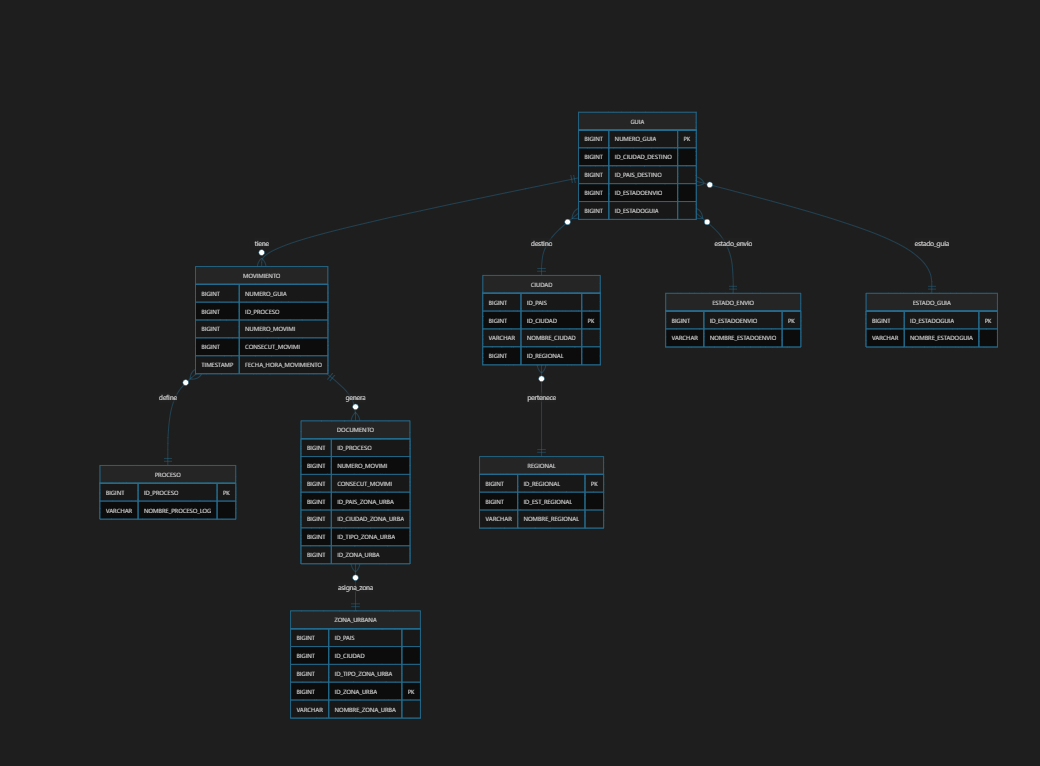
```mermaid
erDiagram
    GUIA {
        BIGINT NUMERO_GUIA PK
        BIGINT ID_CIUDAD_DESTINO
        BIGINT ID_PAIS_DESTINO
        BIGINT ID_ESTADOENVIO
        BIGINT ID_ESTADOGUIA
    }

    MOVIMIENTO {
        BIGINT NUMERO_GUIA
        BIGINT ID_PROCESO
        BIGINT NUMERO_MOVIMI
        BIGINT CONSECUT_MOVIMI
        TIMESTAMP FECHA_HORA_MOVIMIENTO
    }

    DOCUMENTO {
        BIGINT ID_PROCESO
        BIGINT NUMERO_MOVIMI
        BIGINT CONSECUT_MOVIMI
        BIGINT ID_PAIS_ZONA_URBA
        BIGINT ID_CIUDAD_ZONA_URBA
        BIGINT ID_TIPO_ZONA_URBA
        BIGINT ID_ZONA_URBA
    }

    CIUDAD {
        BIGINT ID_PAIS
        BIGINT ID_CIUDAD PK
        VARCHAR NOMBRE_CIUDAD
        BIGINT ID_REGIONAL
    }

    REGIONAL {
        BIGINT ID_REGIONAL PK
        BIGINT ID_EST_REGIONAL
        VARCHAR NOMBRE_REGIONAL
    }

    ESTADO_ENVIO {
        BIGINT ID_ESTADOENVIO PK
        VARCHAR NOMBRE_ESTADOENVIO
    }

    ESTADO_GUIA {
        BIGINT ID_ESTADOGUIA PK
        VARCHAR NOMBRE_ESTADOGUIA
    }

    PROCESO {
        BIGINT ID_PROCESO PK
        VARCHAR NOMBRE_PROCESO_LOG
    }

    ZONA_URBANA {
        BIGINT ID_PAIS
        BIGINT ID_CIUDAD
        BIGINT ID_TIPO_ZONA_URBA
        BIGINT ID_ZONA_URBA PK
        VARCHAR NOMBRE_ZONA_URBA
    }

    GUIA ||--o{ MOVIMIENTO : tiene
    MOVIMIENTO }o--|| PROCESO : define
    MOVIMIENTO ||--o{ DOCUMENTO : genera
    GUIA }o--|| CIUDAD : destino
    CIUDAD }o--|| REGIONAL : pertenece
    GUIA }o--|| ESTADO_ENVIO : estado_envio
    GUIA }o--|| ESTADO_GUIA : estado_guia
    DOCUMENTO }o--|| ZONA_URBANA : asigna_zona
```

### Interpretación de las relaciones
- `GUIA` es la entidad principal. Cada guía tiene uno o varios movimientos.
- `MOVIMIENTO` registra cada cambio de estado o evento de la guía; cada movimiento se asocia a un `PROCESO`.
- `DOCUMENTO` está ligado al movimiento mediante `ID_PROCESO + NUMERO_MOVIMI + CONSECUT_MOVIMI`.
- `ZONA_URBANA` se obtiene desde el documento a través de `ID_PAIS_ZONA_URBA`, `ID_CIUDAD_ZONA_URBA`, `ID_TIPO_ZONA_URBA` y `ID_ZONA_URBA`.
- `CIUDAD` y `REGIONAL` complementan la dimensión geográfica de la guía.
- `ESTADO_ENVIO` y `ESTADO_GUIA` completan los atributos de estado del envío y de la guía.

### Relación de la consulta
La consulta filtrada hace esta lógica:
- `GUIA` ↔ `MOVIMIENTO` por `NUMERO_GUIA`
- `MOVIMIENTO` ↔ `DOCUMENTO` por `ID_PROCESO`, `NUMERO_MOVIMI`, `CONSECUT_MOVIMI`
- `DOCUMENTO` ↔ `ZONA_URBANA` por `ID_PAIS_ZONA_URBA`, `ID_CIUDAD_ZONA_URBA`, `ID_TIPO_ZONA_URBA`, `ID_ZONA_URBA`
- `GUIA` ↔ `CIUDAD` por `ID_CIUDAD_DESTINO` / `ID_PAIS_DESTINO`
- `CIUDAD` ↔ `REGIONAL` por `ID_REGIONAL`
- `GUIA` ↔ `ESTADO_ENVIO` y `ESTADO_GUIA` por sus IDs
- `MOVIMIENTO` ↔ `PROCESO` por `ID_PROCESO`


---

## Etapa 1 (proyecto, sección 4.5.1): Análisis exploratorio y caracterización

Lo que sigue completa lo que pide el proyecto para esta etapa y que el notebook aún no cubría:
la distribución del tiempo de entrega, la tasa global y desagregada de incumplimiento de SLA, los
patrones temporales y espaciales, y las relaciones bivariadas entre las predictoras candidatas y las
dos variables objetivo (`tiempo de entrega`, `incumplimiento de SLA`).

Todo lo de arriba (extracción y revisión tabla por tabla) ya identificaba la estructura de cada fuente;
de aquí en adelante se combinan esas fuentes para caracterizar el fenómeno, que es lo que el
objetivo específico 1 del proyecto pide entregar.

### 1.1 Diagnóstico previo: identificar los campos que definen `tiempo de entrega` e `incumplimiento de SLA`

Antes de calcular nada hace falta confirmar dos cosas que el notebook original no dejaba explícitas:

1. Qué valor(es) de `ID_PROCESO` en `LOG.SEGUIMIENTO_ENVIO` corresponden al evento de **entrega efectiva**
   (la extracción ya filtra `ID_PROCESO IN (5, 6, 9)`, lo que sugiere que la entrega es uno de esos tres,
   pero no hay evidencia en el notebook de cuál).
2. Con qué campo se compara la entrega para saber si hubo **incumplimiento de SLA** (el anteproyecto habla
   de un "tiempo de tránsito comprometido" — sección 4.3.1 — que debe existir en alguna tabla paramétrica
   o derivarse de `ID_ESTADOGUIA`/`ID_ESTADOENVIO`, pero ese campo no apareció en las tablas revisadas arriba).

La celda siguiente imprime el contenido completo (no solo 5 filas) de las tablas paramétricas relevantes
para que este mapeo se pueda hacer a ojo. **Ejecutar esto primero y completar la sección de configuración
(1.2) con los valores reales antes de correr el resto del notebook.**

In [0]:
# Diagnóstico: contenido completo de las tablas que definen procesos y estados
# (a diferencia de las celdas anteriores, aquí no se trunca con LIMIT 5)

df_procesos = duckdb.sql(f"""
    SELECT * FROM read_parquet('{parquet_path_CONSULTA_PAR_PROCESOS}') ORDER BY ID_PROCESO
""").df()
print(f"PAR.PROCESOS ({len(df_procesos)} filas) -- revisar cuál ID_PROCESO representa 'entrega al cliente'")
display(df_procesos)

df_estadosguia = duckdb.sql(f"""
    SELECT * FROM read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSGUIA}') ORDER BY ID_ESTADOGUIA
""").df()
print(f"PAR.ESTADOSGUIA ({len(df_estadosguia)} filas)")
display(df_estadosguia)

df_estadosenvio = duckdb.sql(f"""
    SELECT * FROM read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSENVIO}') ORDER BY ID_ESTADOENVIO
""").df()
print(f"PAR.ESTADOSENVIO ({len(df_estadosenvio)} filas)")
display(df_estadosenvio)

# Estructura completa de GUIAS: buscar cualquier columna que luzca como fecha/tiempo de compromiso
# (p. ej. FECHA_COMPROMISO, DIAS_TRANSITO, FECHA_LIMITE, etc.)
df_guias_schema = duckdb.sql(f"""
    DESCRIBE SELECT * FROM read_parquet('{PARQUET_CONSULTA_GUIAS}')
""").df()
print("Columnas disponibles en LOG.GUIAS:")
display(df_guias_schema)

PAR.PROCESOS (52 filas) -- revisar cuál ID_PROCESO representa 'entrega al cliente'


ID_PROCESO,ID_ESTADOENVIO,ID_ESTADOGUIA,NOMBRE_PROCESO_LOG,CRUZA_DOCUMENTO,ID_PIDE_TIPOENVIO,ID_PIDE_ESFISI_DOCU,ID_TIPO_PROCESO,ID_PIDE_CONC_MOVI,LUGAR_ORIG_MOVIMI,LUGAR_SEGUN_MOVIMI,ID_PIDE_SELLO_SEGURO,ID_PIDE_UBICACION_DIVISION,ID_PIDE_OPERATIVO,ID_PIDE_VEHICULO,ID_DOCU_CRUZA,DESC_MENSAJE1,DESC_MENSAJE2,ID_VIEW_CLIE,ID_PIDE_DOCU_DOCU,ID_PIDE_TIPOCONT,ID_PIDE_SUBPRODUCTO,ID_EST_PROCESO,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,msrepl_tran_version,FECHA_EXTRACCION_DW
1,9,3,ALISTAMIENTO CLIENTE CORPORATIVO,0,1,1,2,1,2,1,1,1,1,1,0,GUIA GENERADA,GUIA GENERADA,1,1,1,1,1,FORERTJE,2001-11-30T14:58:43.000Z,2025-10-31T19:04:26.437Z,1771661F-977D-4C22-9AC4-9CA166E42C3E,2026-08-29T01:02:52.000Z
2,1,3,ADMISION DEL ENVIO,0,1,1,2,0,1,1,1,1,1,1,0,ADMISION DEL ENVIO EN CDS,ADMISION DEL ENVIO EN CDS,1,1,1,1,1,FORERTJE,2001-11-30T15:51:42.000Z,2025-10-31T18:59:37.990Z,01BD12E9-99DA-42E2-A97C-AEE79B758432,2026-08-29T01:02:52.000Z
3,9,3,ALISTAMIENTO CLIENTE PARA RECOLECCIONES,0,0,0,1,0,2,1,0,0,0,0,0,ALISTAMIENTO CLIENTE PARA ENTREGA A RECOLECCIONES,ALISTAMIENTO CLIENTE PARA ENTREGA A RECOLECCIONES,1,0,0,0,1,FORERTJE,2001-12-26T09:36:27.000Z,2025-10-31T19:01:21.880Z,BBB3A2BF-C8DB-424E-9831-EFBC51A0A314,2026-08-29T01:02:52.000Z
4,1,3,ALISTAMIENTO CDS PARA RECOLECCIONES,0,0,0,2,0,1,1,0,0,0,0,0,ALISTAMIENTO CDS PARA ENTREGAR A RECOLECCIONES,ALISTAMIENTO CDS PARA ENTREGAR A RECOLECCIONES,1,0,0,0,1,FORERTJE,2001-12-26T09:37:16.000Z,2025-10-31T19:02:25.403Z,508783C4-DCDF-4AEA-A6DB-7FDA317DFD73,2026-08-29T01:02:52.000Z
5,2,3,ENTRADA PUNTO DE SERVICIO,0,0,0,1,0,4,2,0,0,0,0,0,INGRESO AL CENTRO LOGISTICO,INGRESO AL CENTRO LOGISTICO,1,0,0,0,1,camposm,2001-12-26T09:37:51.000Z,2022-05-29T19:48:51.143Z,16A67748-AAED-4EFA-A56C-405A5F6E3F1A,2026-08-29T01:02:52.000Z
6,2,3,ENTRADA DE ZONA URBANA,0,0,0,1,0,2,1,0,0,0,0,0,INGRESO AL CENTRO LOGISTICO,INGRESO AL CENTRO LOGISTICO,1,0,0,0,1,camposm,2001-12-26T09:38:42.000Z,2022-05-29T19:54:03.833Z,0F4F4238-0730-4DCD-B94E-CBD7BCC4A6A0,2026-08-29T01:02:52.000Z
7,2,3,SALIDA A BODEGA LOCAL,0,0,0,2,0,1,1,0,0,0,0,0,SALIDA A BODEGA LOCAL,SALIDA A BODEGA LOCAL,0,0,0,0,1,PULIDDC,2001-12-26T09:39:26.000Z,2020-11-09T20:43:17.330Z,F72B39B7-6B74-47B2-A34C-0E7B2D5E0E9B,2026-08-29T01:02:52.000Z
8,2,3,ENTRADA BODEGA LOCAL,0,0,0,1,0,1,1,0,0,0,0,0,ENTRADA BODEGA LOCAL,ENTRADA BODEGA LOCAL,0,0,0,0,1,PULIDDC,2001-12-26T09:40:04.000Z,2020-11-09T20:43:17.330Z,0D08028E-C307-4462-9539-8B33ADAFEB15,2026-08-29T01:02:52.000Z
9,2,3,SALIDA A ZONA URBANA,0,0,0,2,1,1,2,0,1,0,0,0,EN ZONA DE DISTRIBUCION,EN ZONA DE DISTRIBUCION,1,0,0,0,1,PULIDDC,2001-12-26T09:41:37.000Z,2020-11-09T20:43:17.330Z,3D268EEC-0B44-48A8-BE1F-E0A506B16CAD,2026-08-29T01:02:52.000Z
10,2,3,DEVOLUCION ZONA URBANA,0,1,1,1,1,2,1,1,1,1,1,0,INGRESO AL CENTRO LOGISTICO POR DEVOLUCION,INGRESO AL CENTRO LOGISTICO POR DEVOLUCION,1,1,1,1,1,PULIDDC,2001-12-04T16:16:12.000Z,2020-11-09T20:43:17.330Z,6825E0E8-D2CA-41F5-9547-0CB1D3A3317A,2026-08-29T01:02:52.000Z


PAR.ESTADOSGUIA (12 filas)


ID_ESTADOGUIA,NOMBRE_ESTADOGUIA,ENVIO_ACEPTA_MOVIMIENTOS,ID_EST_ESTADOGUIA,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,msrepl_tran_version,FECHA_EXTRACCION_DW
1,DISPONIBLE,1,1,PITAHS,2002-04-08T16:33:17.000Z,2012-11-23T17:09:55.447Z,0FF44899-BCFA-4F63-B184-3DCBE8BE3E95,2026-08-29T01:02:52.000Z
2,ASIGNADA,1,1,SoportePE,2002-04-08T16:33:47.000Z,2018-08-13T16:19:27.710Z,2125A43E-74B2-4370-91B4-EF7144D1BE83,2026-08-29T01:02:52.000Z
3,UTILIZADA,1,1,SoportePE,2002-04-08T16:34:05.000Z,2018-08-13T16:19:53.703Z,29ED68DB-9BA1-40D6-9B39-C82996F1E654,2026-08-29T01:02:52.000Z
4,ANULADA,0,1,SoportePE,2002-04-08T16:34:21.000Z,2018-08-13T16:20:19.263Z,22E64B79-DBA8-4BF9-A371-F78BB79C7EEF,2026-08-29T01:02:52.000Z
5,PENDIENTE POR BORRAR,0,1,GARCIJP,2002-04-08T16:34:46.000Z,2002-04-08T16:34:46.000Z,E7C3A797-4B31-4354-9D99-E6816657690B,2026-08-29T01:02:52.000Z
6,GUIA REEMPLAZADA,1,1,CASTAJE,2002-04-08T16:35:14.000Z,2004-08-02T17:00:24.487Z,122EB338-73E7-4A5F-A332-D11A8ED9AA1D,2026-08-29T01:02:52.000Z
7,DIGITADA,1,1,PITAHS,2002-04-08T16:35:42.000Z,2012-10-31T18:15:23.173Z,F8CF615F-BC6E-49FD-B7E1-73C60A7BF2D5,2026-08-29T01:02:52.000Z
8,DIGITALIZADA,1,1,CastaJE,2002-04-08T16:36:11.000Z,2012-11-14T11:05:43.310Z,53EBCFAA-030C-4B81-9A1D-F0BAE948E062,2026-08-29T01:02:52.000Z
9,EN ARCHIVO,0,1,castaJE,2002-04-08T16:36:28.000Z,2004-09-14T15:04:51.070Z,1394362A-9909-4E8C-A8A4-1D27B63E73E1,2026-08-29T01:02:52.000Z
10,ENTREGADO,0,1,Diazcm,2003-02-08T12:31:22.000Z,2015-06-13T14:55:40.140Z,CBCD6628-5040-4F8C-88CE-1B79A4525D6E,2026-08-29T01:02:52.000Z


PAR.ESTADOSENVIO (8 filas)


ID_ESTADOENVIO,NOMBRE_ESTADOENVIO,ID_EST_ESTADOENVIO,LOGIN_EMPLEADO,FECHA_CREACION,FECHA_MODIFICACION,msrepl_tran_version,FECHA_EXTRACCION_DW
1,RECIBIDO DEL CLIENTE,1,biancd,2002-04-05T08:57:02.000Z,2018-08-13T15:32:36.693Z,328D888E-A658-49FC-8FD7-67674CBE35C1,2026-08-29T01:02:52.000Z
2,EN PROCESAMIENTO,1,biancd,2002-04-05T08:57:30.000Z,2018-08-13T15:33:43.910Z,8B91DCCD-DA24-47D6-A2D9-79D2701560C0,2026-08-29T01:02:52.000Z
3,ENTREGADO,1,biancd,2002-04-05T08:57:53.000Z,2018-08-13T15:33:23.067Z,26C342A9-DF39-4FDE-9A09-4F4399BE1B9B,2026-08-29T01:02:52.000Z
4,ENTREGADO A REMITENTE,1,biancd,2007-11-06T11:53:16.730Z,2018-08-13T15:34:01.820Z,08494EAD-715C-48DB-9202-C060A0D36ADC,2026-08-29T01:02:52.000Z
5,SINIESTRADO,1,biancd,2010-11-16T15:04:11.167Z,2018-08-13T15:34:22.197Z,922FF635-756B-46F5-8B59-4B9DDD45D5D5,2026-08-29T01:02:52.000Z
6,ENVIO REEXPEDICION,1,castaje,2017-01-05T15:17:08.690Z,2017-01-05T15:23:56.317Z,null,2026-08-29T01:02:52.000Z
7,GUIA GENERADA,1,molinmm,2017-03-16T12:40:54.590Z,2018-02-19T11:37:22.460Z,null,2026-08-29T01:02:52.000Z
9,EN ALISTAMIENTO DEL CLIENTE,1,FORERTJE,2025-10-31T18:54:50.560Z,2025-10-31T18:54:50.560Z,null,2026-08-29T01:02:52.000Z


Columnas disponibles en LOG.GUIAS:


column_name,column_type,null,key,default,extra
NUMERO_GUIA,DOUBLE,YES,null,null,null
ID_TIPOGUIA,BIGINT,YES,null,null,null
ID_CLIENTE,VARCHAR,YES,null,null,null
ID_CANAL,DOUBLE,YES,null,null,null
ID_DIVISION_PROV,DOUBLE,YES,null,null,null
ID_1,BIGINT,YES,null,null,null
ID_2,BIGINT,YES,null,null,null
ID_PAIS_ORIGEN,BIGINT,YES,null,null,null
ID_CIUDAD_ORIGEN,BIGINT,YES,null,null,null
ID_PAIS_DESTINO,DOUBLE,YES,null,null,null


### 1.2 Configuración: parámetros de negocio que hay que confirmar con el equipo/los datos

Completar estos valores con lo que arroje el diagnóstico anterior. Se dejan explícitos y separados del resto
del código para que quede claro qué es una decisión de negocio (que alguien debe validar) y qué es cálculo.

- `ID_PROCESO_ENTREGA`: el/los `ID_PROCESO` de `LOG.SEGUIMIENTO_ENVIO` que marcan la entrega efectiva del envío.
- `ID_PROCESO_INICIO`: el `ID_PROCESO` (o el uso de `GUI.FECHA_ENVIO`) que marca el inicio del tránsito.
- `CAMPO_SLA_DIAS`: el campo (propio de la guía, de la zona o de una tabla paramétrica de acuerdos) con el
  tiempo de tránsito comprometido. Si no existe como campo explícito, se deja `None` y se documenta como
  limitación (el proyecto ya anticipa esto en 4.10.3: "disponibilidad retrospectiva de variables").


**Actualización:** `CAMPO_SLA_DIAS` ya se resolvió con `PAR.RED_OPERATIVA_OFERTA.TIEMPO_ENTREGA_COMERCIAL_HOR/_DIA` (tiempo de tránsito comprometido por ruta), la misma tabla que ya usa `0300_CleanTransformParquet_1.ipynb`. `SLA_DIAS_DEFAULT` queda solo como respaldo para las rutas que no tengan esa combinación parametrizada.

In [0]:
# AJUSTAR estos tres valores según lo observado en la celda de diagnóstico (1.1)
ID_PROCESO_ENTREGA = [9]          # TODO: confirmar contra PAR.PROCESOS (ej. "ENTREGADO A DESTINATARIO")
ID_PROCESO_INICIO = None          # TODO: si hay un ID_PROCESO de "recibido del cliente"; si no, se usa GUI.FECHA_ENVIO
CAMPO_SLA_DIAS = 'TIEMPO_ENTREGA_COMERCIAL_HOR (PAR.RED_OPERATIVA_OFERTA)'  # ya resuelto: ver celda 1.3 / preview de arriba
SLA_DIAS_DEFAULT = 3              # Valor de referencia solo si CAMPO_SLA_DIAS es None (ajustar con el acuerdo real de SERVIENVIOS)

print("Configuración activa:")
print(f"  ID_PROCESO_ENTREGA = {ID_PROCESO_ENTREGA}")
print(f"  ID_PROCESO_INICIO  = {ID_PROCESO_INICIO}")
print(f"  CAMPO_SLA_DIAS     = {CAMPO_SLA_DIAS}")
print(f"  SLA_DIAS_DEFAULT   = {SLA_DIAS_DEFAULT} (usado solo si no hay CAMPO_SLA_DIAS)")

Configuración activa:
  ID_PROCESO_ENTREGA = [9]
  ID_PROCESO_INICIO  = None
  CAMPO_SLA_DIAS     = TIEMPO_ENTREGA_COMERCIAL_HOR (PAR.RED_OPERATIVA_OFERTA)
  SLA_DIAS_DEFAULT   = 3 (usado solo si no hay CAMPO_SLA_DIAS)


### 1.3 Construcción de la tabla base de análisis (a nivel de envío)

Une guías + movimientos + parametrías para obtener, por cada `NUMERO_GUIA`, la fecha de inicio, la fecha
de entrega, el `tiempo de entrega` (variable objetivo continua, sección 4.3.1) y el indicador de
`incumplimiento de SLA` (variable objetivo binaria). Se agregan también las dimensiones temporales,
espaciales y de operación que el proyecto lista en la tabla de la sección 4.3.2, para poder cruzarlas
contra las dos variables objetivo más abajo.

Por ahora se usa el periodo `202601` (igual que el resto del notebook) para no procesar todo el histórico en
cada corrida exploratoria; una vez el análisis quede validado, se puede repetir sobre todos los periodos de
`ExtraccionInformacion.ipynb` para construir la base analítica completa de la Etapa 2.

In [0]:
# Vista previa de PAR.RED_OPERATIVA_OFERTA: esta es la tabla que trae el tiempo de transito
# COMPROMETIDO por ruta (TIEMPO_ENTREGA_COMERCIAL_HOR / _DIA) -- es el campo real que responde
# el CAMPO_SLA_DIAS que quedo en None en la celda de configuracion (1.2). Se usa mas abajo en la
# construccion de df_base, igual que ya se resolvio en 0300_CleanTransformParquet_1.ipynb.
df_resultado = duckdb.sql(f"""
    SELECT *
    FROM read_parquet('{parquet_path_CONSULTA_PAR_RED_OPERATIVA_OFERTA}')
    LIMIT 5
""").df()
print(columns := df_resultado.columns)
display(df_resultado)

Index(['ID_RUTA', 'REGIONAL_ORIGEN', 'CIUDAD_ORIGEN', 'ID_CIUDAD_ORIGEN',
       'REGIONAL_DESTINO', 'CIUDAD_DESTINO', 'ID_CIUDAD_DESTINO',
       'NOMBRE_TIEMPO', 'ID_TIEMPO', 'NOMBRE_MEDTRANS', 'ID_MEDTRANS',
       'NOMBRE_IMPEDANCIA', 'ID_IMPEDANCIA', 'NOMBRE_FILTRO',
       'ID_FILTRO_CRITICIDAD', 'VALOR_FILTRO_CRITICIDAD',
       'VALOR_FILTRO_MODO_TRANSPORTE', 'TOTAL_TIEMPO_OPERATIVO',
       'TOTAL_TIEMPO_OPERATIVO_REF', 'TOTAL_DISTANCIA', 'TOTAL_COSTO',
       'TOTAL_ID_CRITICIDAD', 'TOTAL_ID_PESOCATEG',
       'LOGIN_EMPLEADO_MODIFICACION', 'FECHA_MODIFICACION', 'ID_ESTADO_RUTA',
       'ID_RUTA_NET', 'TOTAL_TIEMPO_OPERATIVO_REF_CALCULO',
       'TOTAL_DISTANCIA_CALCULO', 'TIEMPO_ENTREGA_COMERCIAL_HOR',
       'TIEMPO_ENTREGA_COMERCIAL_DIA', 'LOGIN_MODIFICACION_MANUAL'],
      dtype='object')


ID_RUTA,REGIONAL_ORIGEN,CIUDAD_ORIGEN,ID_CIUDAD_ORIGEN,REGIONAL_DESTINO,CIUDAD_DESTINO,ID_CIUDAD_DESTINO,NOMBRE_TIEMPO,ID_TIEMPO,NOMBRE_MEDTRANS,ID_MEDTRANS,NOMBRE_IMPEDANCIA,ID_IMPEDANCIA,NOMBRE_FILTRO,ID_FILTRO_CRITICIDAD,VALOR_FILTRO_CRITICIDAD,VALOR_FILTRO_MODO_TRANSPORTE,TOTAL_TIEMPO_OPERATIVO,TOTAL_TIEMPO_OPERATIVO_REF,TOTAL_DISTANCIA,TOTAL_COSTO,TOTAL_ID_CRITICIDAD,TOTAL_ID_PESOCATEG,LOGIN_EMPLEADO_MODIFICACION,FECHA_MODIFICACION,ID_ESTADO_RUTA,ID_RUTA_NET,TOTAL_TIEMPO_OPERATIVO_REF_CALCULO,TOTAL_DISTANCIA_CALCULO,TIEMPO_ENTREGA_COMERCIAL_HOR,TIEMPO_ENTREGA_COMERCIAL_DIA,LOGIN_MODIFICACION_MANUAL
8158670,EJE CAFETERO,PURIFICACION,487,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,14400.0,14400.0,1.0,null,null,null,RF469080,2021-10-04T10:07:44.680Z,true,null,null,null,240.0,10.0,RENGIDM
8158671,NORTE,GUAMAL (MAG),488,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,11520.0,11520.0,1.0,null,null,null,RF462748,2021-10-01T07:29:14.920Z,true,null,null,null,192.0,8.0,BROCHYC
8158672,EJE CAFETERO,ROVIRA,489,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,15840.0,15840.0,1.0,null,null,null,RF469080,2021-10-04T09:56:16.153Z,true,null,null,null,264.0,11.0,RENGIDM
8158673,EJE CAFETERO,SALDAÑA,490,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,14400.0,14400.0,1.0,null,null,null,RF469080,2021-10-04T09:56:23.650Z,true,null,null,null,240.0,10.0,RENGIDM
8158674,EJE CAFETERO,VENADILLO,491,ANTIOQUIA,SAN JACINTO DEL CAUCA,8095,NORMAL,1,TERRESTRE,1,TIEMPO,1,null,null,null,null,14400.0,14400.0,1.0,null,null,null,RF469080,2021-10-04T09:59:49.497Z,true,null,null,null,240.0,10.0,RENGIDM


In [0]:
if not ID_PROCESO_ENTREGA:
    print("La lista ID_PROCESO_ENTREGA está vacía.")
else:
    query = f"""
        WITH MOV_RANQUEADOS AS (
            SELECT
                CAST(NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA,
                ID_PROCESO,
                NUMERO_MOVIMI,
                CONSECUT_MOVIMI,
                FECHA_HORA_MOVIMIENTO,
                ROW_NUMBER() OVER (
                    PARTITION BY CAST(NUMERO_GUIA AS BIGINT)
                    ORDER BY FECHA_HORA_MOVIMIENTO ASC
                ) AS RN
            FROM read_parquet('{PARQUET_CONSULTA_MOVIMIENTOS}')
            WHERE ID_PROCESO = ANY(?)
        ),
        ENTREGA AS (
            SELECT NUMERO_GUIA, ID_PROCESO, NUMERO_MOVIMI, CONSECUT_MOVIMI, FECHA_HORA_MOVIMIENTO AS FECHA_ENTREGA
            FROM MOV_RANQUEADOS
            WHERE RN = 1
        ),
        -- PREVENIR FAN-OUT: Asegurar 1 sola fila por movimiento en DOCUMENTOS
        DOC_UNICO AS (
            SELECT *
            FROM read_parquet('{PARQUET_CONSULTA_DOCUMENTOS}')
            QUALIFY ROW_NUMBER() OVER (
                PARTITION BY ID_PROCESO, NUMERO_MOVIMI, CONSECUT_MOVIMI 
                ORDER BY ID_PROCESO
            ) = 1
        ),
        -- PREVENIR FAN-OUT: Asegurar 1 sola fila por ruta en RED OPERATIVA
        RED_UNICA AS (
            SELECT *
            FROM read_parquet('{parquet_path_CONSULTA_PAR_RED_OPERATIVA_OFERTA}')
            QUALIFY ROW_NUMBER() OVER (
                PARTITION BY ID_CIUDAD_ORIGEN, ID_CIUDAD_DESTINO, ID_TIEMPO, ID_MEDTRANS
                ORDER BY ID_CIUDAD_ORIGEN
            ) = 1
        )
        SELECT
            CAST(GUI.NUMERO_GUIA AS BIGINT) AS NUMERO_GUIA,
            GUI.FECHA_ENVIO,
            ENTREGA.FECHA_ENTREGA,
            DATEDIFF('hour', GUI.FECHA_ENVIO, ENTREGA.FECHA_ENTREGA) AS TIEMPO_ENTREGA_HORAS,
            RED.TIEMPO_ENTREGA_COMERCIAL_HOR,
            CASE
                WHEN RED.TIEMPO_ENTREGA_COMERCIAL_HOR IS NOT NULL
                    THEN (DATEDIFF('hour', GUI.FECHA_ENVIO, ENTREGA.FECHA_ENTREGA) > RED.TIEMPO_ENTREGA_COMERCIAL_HOR)::INT
                ELSE (DATEDIFF('hour', GUI.FECHA_ENVIO, ENTREGA.FECHA_ENTREGA) > {SLA_DIAS_DEFAULT} * 24)::INT
            END AS INCUMPLIO_SLA,
            DATE_PART('hour', GUI.FECHA_ENVIO) AS HORA_SALIDA,
            DATE_PART('dow', GUI.FECHA_ENVIO) AS DIA_SEMANA,
            DATE_PART('month', GUI.FECHA_ENVIO) AS MES,
            CIU_DEST.NOMBRE_CIUDAD AS CIUDAD_DESTINO,
            REGIO.NOMBRE_REGIONAL AS NOMBRE_REGIONAL,
            ZONA.NOMBRE_ZONA_URBA AS NOMBRE_ZONA_URBANA,
            EST_GUIA.NOMBRE_ESTADOGUIA AS NOMBRE_ESTADO_GUIA
        FROM read_parquet('{PARQUET_CONSULTA_GUIAS}') AS GUI
        INNER JOIN ENTREGA ON ENTREGA.NUMERO_GUIA = CAST(GUI.NUMERO_GUIA AS BIGINT)
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_CIUDADES}') AS CIU_DEST
            ON GUI.ID_CIUDAD_DESTINO = CIU_DEST.ID_CIUDAD AND GUI.ID_PAIS_DESTINO = CIU_DEST.ID_PAIS
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_REGIONALES_PAIS}') AS REGIO
            ON REGIO.ID_REGIONAL = CIU_DEST.ID_REGIONAL
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_ESTADOSGUIA}') AS EST_GUIA
            ON GUI.ID_ESTADOGUIA = EST_GUIA.ID_ESTADOGUIA
        LEFT JOIN DOC_UNICO AS DOC
            ON DOC.ID_PROCESO = ENTREGA.ID_PROCESO
            AND DOC.NUMERO_MOVIMI = ENTREGA.NUMERO_MOVIMI
            AND DOC.CONSECUT_MOVIMI = ENTREGA.CONSECUT_MOVIMI
        LEFT JOIN read_parquet('{parquet_path_CONSULTA_PAR_ZONASURBANAS}') AS ZONA
            ON DOC.ID_PAIS_ZONA_URBA = ZONA.ID_PAIS
            AND DOC.ID_CIUDAD_ZONA_URBA = ZONA.ID_CIUDAD
            AND DOC.ID_TIPO_ZONA_URBA = ZONA.ID_TIPO_ZONA_URBA
            AND DOC.ID_ZONA_URBA = ZONA.ID_ZONA_URBA
        LEFT JOIN RED_UNICA AS RED
            ON GUI.ID_CIUDAD_ORIGEN = RED.ID_CIUDAD_ORIGEN
            AND GUI.ID_CIUDAD_DESTINO = RED.ID_CIUDAD_DESTINO
            AND CASE WHEN COALESCE(GUI.ID_TIEMPO,0) <> 0 THEN GUI.ID_TIEMPO ELSE 1 END = RED.ID_TIEMPO
            AND CASE WHEN COALESCE(GUI.ID_MEDTRANS,0) <> 0 THEN GUI.ID_MEDTRANS ELSE 1 END = RED.ID_MEDTRANS
    """

    df_base = duckdb.sql(query, params=[ID_PROCESO_ENTREGA]).df()

    print(f"Envios en la base de analisis: {len(df_base):,}")
    assert df_base["NUMERO_GUIA"].is_unique, "df_base deberia tener una fila por guia -- revisar fan-out en los LEFT JOIN"
    print(f"Guias sin tiempo comercial de referencia (INCUMPLIO_SLA calculado con SLA_DIAS_DEFAULT): "
          f"{df_base['TIEMPO_ENTREGA_COMERCIAL_HOR'].isna().mean():.1%}")
    display(df_base.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Envios en la base de analisis: 1,842,407
Guias sin tiempo comercial de referencia (INCUMPLIO_SLA calculado con SLA_DIAS_DEFAULT): 0.0%


NUMERO_GUIA,FECHA_ENVIO,FECHA_ENTREGA,TIEMPO_ENTREGA_HORAS,TIEMPO_ENTREGA_COMERCIAL_HOR,INCUMPLIO_SLA,HORA_SALIDA,DIA_SEMANA,MES,CIUDAD_DESTINO,NOMBRE_REGIONAL,NOMBRE_ZONA_URBANA,NOMBRE_ESTADO_GUIA
2283733108,2026-01-20T12:44:00.000Z,2026-01-21T09:27:57.000Z,21,24.0,0,12,2,1,DOSQUEBRADAS,EJE CAFETERO,R&D DOSQ. DERECHO 1,ENTREGADO
9187857505,2026-01-20T09:30:01.030Z,2026-01-21T10:48:00.000Z,25,24.0,1,9,2,1,BOGOTA,BOGOTA,R&D FONTIBON A,ENTREGADO
9188097201,2026-01-20T09:56:58.557Z,2026-01-21T08:58:02.000Z,23,24.0,0,9,2,1,MEDELLIN,ANTIOQUIA,R&D CONQUISTADORES,ENTREGADO
9187957439,2026-01-20T10:04:02.867Z,2026-01-21T08:27:33.000Z,22,24.0,0,10,2,1,PEREIRA,EJE CAFETERO,R&D DQ IZQUIERDO A,ENTREGADO
9184401601,2026-01-20T11:58:45.683Z,2026-01-21T11:21:02.000Z,24,24.0,0,11,2,1,BOGOTA,BOGOTA,R&D SANTA BARBARA A,ENTREGADO


### 1.4 Distribución del tiempo de entrega

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df_base["TIEMPO_ENTREGA_HORAS"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_base["TIEMPO_ENTREGA_HORAS"], bins=40, ax=axes[0])
axes[0].set_title("Distribución del tiempo de entrega (horas)")
axes[0].set_xlabel("Horas")

sns.boxplot(x=df_base["TIEMPO_ENTREGA_HORAS"], ax=axes[1])
axes[1].set_title("Tiempo de entrega -- outliers")
axes[1].set_xlabel("Horas")

plt.tight_layout()
plt.show()

# Valores negativos o extremos: candidatos a depurar en la Etapa 2 (criterios de exclusión, sección 4.2.2)
n_negativos = (df_base["TIEMPO_ENTREGA_HORAS"] < 0).sum()
print(f"Registros con tiempo de entrega negativo (dato erróneo, a depurar): {n_negativos}")

---------------------------------------------------------------------------
ModuleNotFoundError                       Traceback (most recent call last)
File <command-5284813963298408>, line 2
      1 import matplotlib.pyplot as plt
----> 2 import seaborn as sns
      4 print(df_base["TIEMPO_ENTREGA_HORAS"].describe())
      6 fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ModuleNotFoundError: No module named 'seaborn'

### 1.5 Tasa global y desagregada de incumplimiento de SLA

In [0]:
tasa_global = df_base["INCUMPLIO_SLA"].mean()
print(f"Tasa global de incumplimiento de SLA: {tasa_global:.1%}")
print("(el anteproyecto reporta ~20% para el histórico completo de SERVIENVIOS; comparar como control de calidad)")

for col in ["NOMBRE_ZONA_URBANA", "NOMBRE_REGIONAL", "NOMBRE_ESTADO_GUIA"]:
    print(f"\nTasa de incumplimiento por {col}:")
    display(
        df_base.groupby(col)["INCUMPLIO_SLA"]
        .agg(envios="count", tasa_incumplimiento="mean")
        .sort_values("tasa_incumplimiento", ascending=False)
    )

### 1.6 Patrones temporales (hora, día, mes)

In [0]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_base.groupby("HORA_SALIDA")["INCUMPLIO_SLA"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("Incumplimiento por hora de salida")
axes[0].set_ylabel("Tasa de incumplimiento")

df_base.groupby("DIA_SEMANA")["INCUMPLIO_SLA"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Incumplimiento por día de la semana (0=domingo)")

df_base.groupby("MES")["INCUMPLIO_SLA"].mean().plot(kind="bar", ax=axes[2])
axes[2].set_title("Incumplimiento por mes")

plt.tight_layout()
plt.show()

# Tiempo de entrega promedio por hora de salida (para ver si el efecto es sobre el tiempo, el incumplimiento, o ambos)
display(
    df_base.groupby("HORA_SALIDA")["TIEMPO_ENTREGA_HORAS"].mean().round(1).rename("horas_promedio")
)

### 1.7 Patrones espaciales (por zona)

In [0]:
resumen_zona = (
    df_base.groupby("NOMBRE_ZONA_URBANA")
    .agg(
        envios=("NUMERO_GUIA", "count"),
        tiempo_entrega_prom_h=("TIEMPO_ENTREGA_HORAS", "mean"),
        tasa_incumplimiento=("INCUMPLIO_SLA", "mean"),
    )
    .sort_values("tasa_incumplimiento", ascending=False)
)
display(resumen_zona)

top_zonas = resumen_zona.sort_values("envios", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_zonas.reset_index(), y="NOMBRE_ZONA_URBANA", x="tasa_incumplimiento", ax=ax)
ax.set_title("Tasa de incumplimiento por zona urbana (15 zonas con más envíos)")
plt.tight_layout()
plt.show()

### 1.8 Relaciones bivariadas entre predictoras candidatas y variables objetivo

El proyecto (sección 4.3.2) agrupa las predictoras en cinco dimensiones: temporales, espaciales, de
cliente, de operación y externas/contexto. De las dos primeras ya se vieron patrones arriba; aquí se deja
la matriz de correlación de las variables numéricas disponibles hasta este punto, más un cruce categórico
explícito, como punto de partida. Las variables de cliente, de operación (tipo de vehículo, número de
paradas) y externas (tráfico, clima) todavía no están en el extracto actual -- quedan señaladas como
pendientes para la Etapa 2 (sección 4.5.2 del proyecto), que es donde se integran fuentes externas.

In [0]:
num_cols = ["TIEMPO_ENTREGA_HORAS", "INCUMPLIO_SLA", "HORA_SALIDA", "DIA_SEMANA", "MES"]
corr = df_base[num_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación entre variables temporales y las variables objetivo")
plt.tight_layout()
plt.show()

# Cruce categórico: estado de guía vs. incumplimiento (para detectar estados que ya de por sí anticipan el desenlace)
display(
    pd.crosstab(df_base["NOMBRE_ESTADO_GUIA"], df_base["INCUMPLIO_SLA"], normalize="index").round(3)
)

### 1.9 Síntesis -- factores con mayor relación con el retraso (objetivo específico 1)

*(completar esta celda después de correr el notebook con el mapeo real de `ID_PROCESO_ENTREGA` y
`CAMPO_SLA_DIAS`; el propósito es dejar, en dos o tres párrafos, qué zonas, horas o estados concentran el
incumplimiento, para que la Etapa 2 -- ingeniería de características -- sepa qué variables derivadas priorizar,
tal como lo pide la sección 4.5.1 del anteproyecto.)*

**Pendientes que esta etapa deja identificados para la Etapa 2:**
- Confirmar `ID_PROCESO_ENTREGA`, `ID_PROCESO_INICIO` y `CAMPO_SLA_DIAS` con el equipo o con la documentación
  interna de SERVIENVIOS (sección 1.1-1.2 de este notebook).
- Depurar los registros con `TIEMPO_ENTREGA_HORAS` negativo o fuera de rango (criterios de exclusión, 4.2.2).
- Incorporar variables de cliente, operación y externas (tráfico, clima) que aún no están en el extracto,
  para completar las cinco dimensiones de predictoras de la sección 4.3.2.
- Extender el análisis a todo el periodo 2023-2025 una vez validada la lógica sobre el periodo de prueba (202601).